In [1]:
pip install wfdb matplotlib numpy scipy

In [2]:
!pip install wfdb matplotlib numpy scipy

In [3]:
import wfdb

# Load ECG record 100 from MIT-BIH database
record = wfdb.rdrecord('100', pn_dir='mitdb')

print("ECG record loaded successfully!")

ECG record loaded successfully!


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Extract ECG signal
ecg_signal = record.p_signal[:, 0]

# Sampling frequency
fs = record.fs

print("Dataset loaded successfully!")
print("Sampling Frequency:", fs, "Hz")
print("Total Samples:", len(ecg_signal))

Dataset loaded successfully!
Sampling Frequency: 360 Hz
Total Samples: 650000


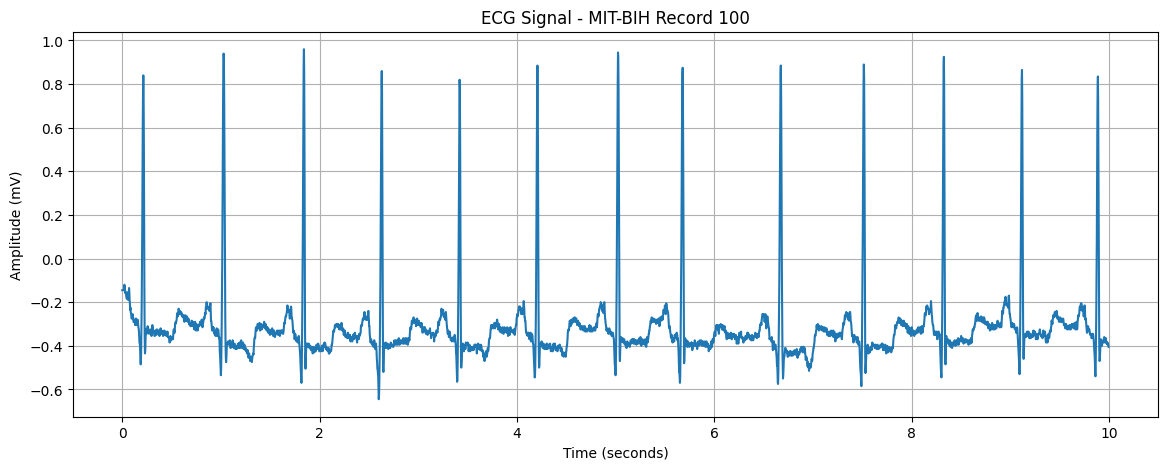

In [5]:
# Select first 10 seconds of ECG
duration = 10

samples = int(duration * fs)

# Create time axis
time = np.arange(samples) / fs

# Extract 10 seconds of signal
ecg_10sec = ecg_signal[:samples]

# Plot ECG
plt.figure(figsize=(14, 5))

plt.plot(time, ecg_10sec)

plt.title("ECG Signal - MIT-BIH Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")

plt.grid(True)
plt.show()

In [6]:
# Generate artificial noise

t = np.arange(len(ecg_10sec)) / fs

# Baseline wander
baseline_noise = 0.15 * np.sin(2 * np.pi * 0.5 * t)

# 50 Hz power-line interference
powerline_noise = 0.05 * np.sin(2 * np.pi * 50 * t)

# Add noise
noisy_ecg = ecg_10sec + baseline_noise + powerline_noise

print("Artificial noise added successfully!")

Artificial noise added successfully!


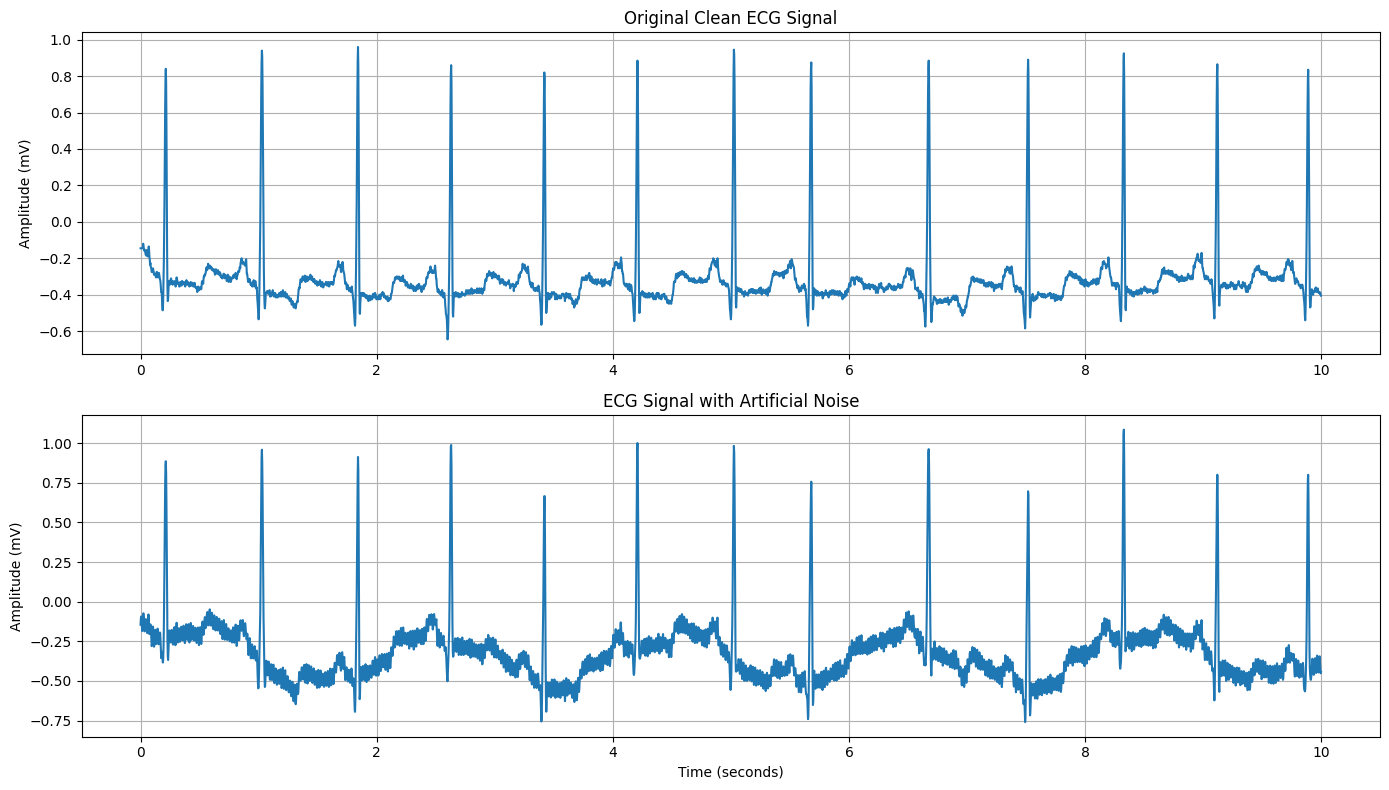

In [7]:
plt.figure(figsize=(14, 8))

# Original ECG
plt.subplot(2, 1, 1)
plt.plot(t, ecg_10sec)
plt.title("Original Clean ECG Signal")
plt.ylabel("Amplitude (mV)")
plt.grid(True)

# Noisy ECG
plt.subplot(2, 1, 2)
plt.plot(t, noisy_ecg)
plt.title("ECG Signal with Artificial Noise")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

# High-pass filter (removes baseline wander)
highpass = butter(2, 0.5, btype='highpass', fs=fs, output='sos')

filtered_ecg = sosfiltfilt(highpass, noisy_ecg)

# Notch filter (removes 50 Hz interference)
b, a = iirnotch(50, 30, fs)

filtered_ecg = filtfilt(b, a, filtered_ecg)

print("ECG Noise Reduction Completed!")

ECG Noise Reduction Completed!


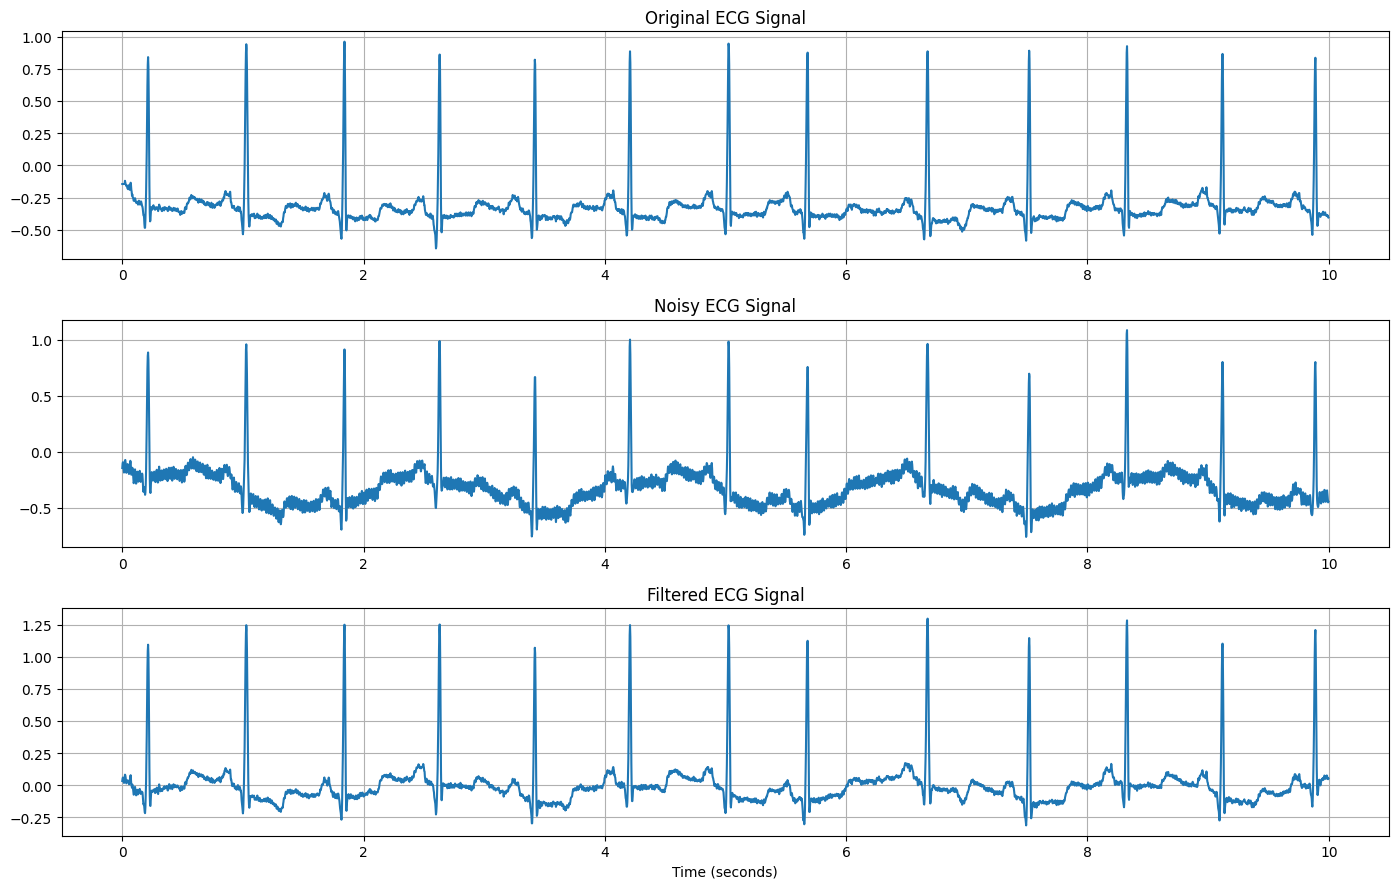

In [9]:
plt.figure(figsize=(14, 9))

plt.subplot(3, 1, 1)
plt.plot(t, ecg_10sec)
plt.title("Original ECG Signal")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(t, noisy_ecg)
plt.title("Noisy ECG Signal")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(t, filtered_ecg)
plt.title("Filtered ECG Signal")
plt.xlabel("Time (seconds)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Calculate MSE
mse = mean_squared_error(ecg_10sec, filtered_ecg)

# Calculate RMSE
rmse = np.sqrt(mse)

# Calculate SNR
def calculate_snr(original, processed):
    noise = original - processed
    signal_power = np.mean(original ** 2)
    noise_power = np.mean(noise ** 2)
    return 10 * np.log10(signal_power / noise_power)

snr = calculate_snr(ecg_10sec, filtered_ecg)

print("MSE:", mse)
print("RMSE:", rmse)
print("SNR:", snr, "dB")

MSE: 0.10638228992661444
RMSE: 0.32616298061952775
SNR: 0.9148179538826408 dB


In [11]:
import numpy as np

# Calculate input noise
input_noise = noisy_ecg - ecg_10sec

# Calculate residual error after filtering
output_error = filtered_ecg - ecg_10sec

# Calculate signal power
signal_power = np.mean(ecg_10sec ** 2)

# Calculate noise power
input_noise_power = np.mean(input_noise ** 2)
output_error_power = np.mean(output_error ** 2)

# Calculate SNR
snr_before = 10 * np.log10(signal_power / input_noise_power)
snr_after = 10 * np.log10(signal_power / output_error_power)

# Calculate improvement
snr_improvement = snr_after - snr_before

print("SNR Before Filtering:", snr_before, "dB")
print("SNR After Filtering:", snr_after, "dB")
print("SNR Improvement:", snr_improvement, "dB")

SNR Before Filtering: 10.214411168493431 dB
SNR After Filtering: 0.9148179538826408 dB
SNR Improvement: -9.29959321461079 dB


In [12]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

# Improved high-pass filter
highpass = butter(
    2, 0.3,
    btype='highpass',
    fs=fs,
    output='sos'
)

# Apply high-pass filter
filtered_ecg_v2 = sosfiltfilt(highpass, noisy_ecg)

# Apply 50 Hz notch filter
b, a = iirnotch(50, 30, fs)

filtered_ecg_v2 = filtfilt(
    b, a, filtered_ecg_v2
)

print("Improved filtering completed!")

Improved filtering completed!


In [13]:
# Calculate filtered signal error
error_v2 = ecg_10sec - filtered_ecg_v2

# Calculate output noise power
noise_power_v2 = np.mean(error_v2 ** 2)

# Calculate new SNR
snr_after_v2 = 10 * np.log10(
    signal_power / noise_power_v2
)

print("Original SNR:", snr_before, "dB")
print("New Filtered SNR:", snr_after_v2, "dB")
print(
    "SNR Improvement:",
    snr_after_v2 - snr_before,
    "dB"
)

Original SNR: 10.214411168493431 dB
New Filtered SNR: 0.710006176554404 dB
SNR Improvement: -9.504404991939026 dB


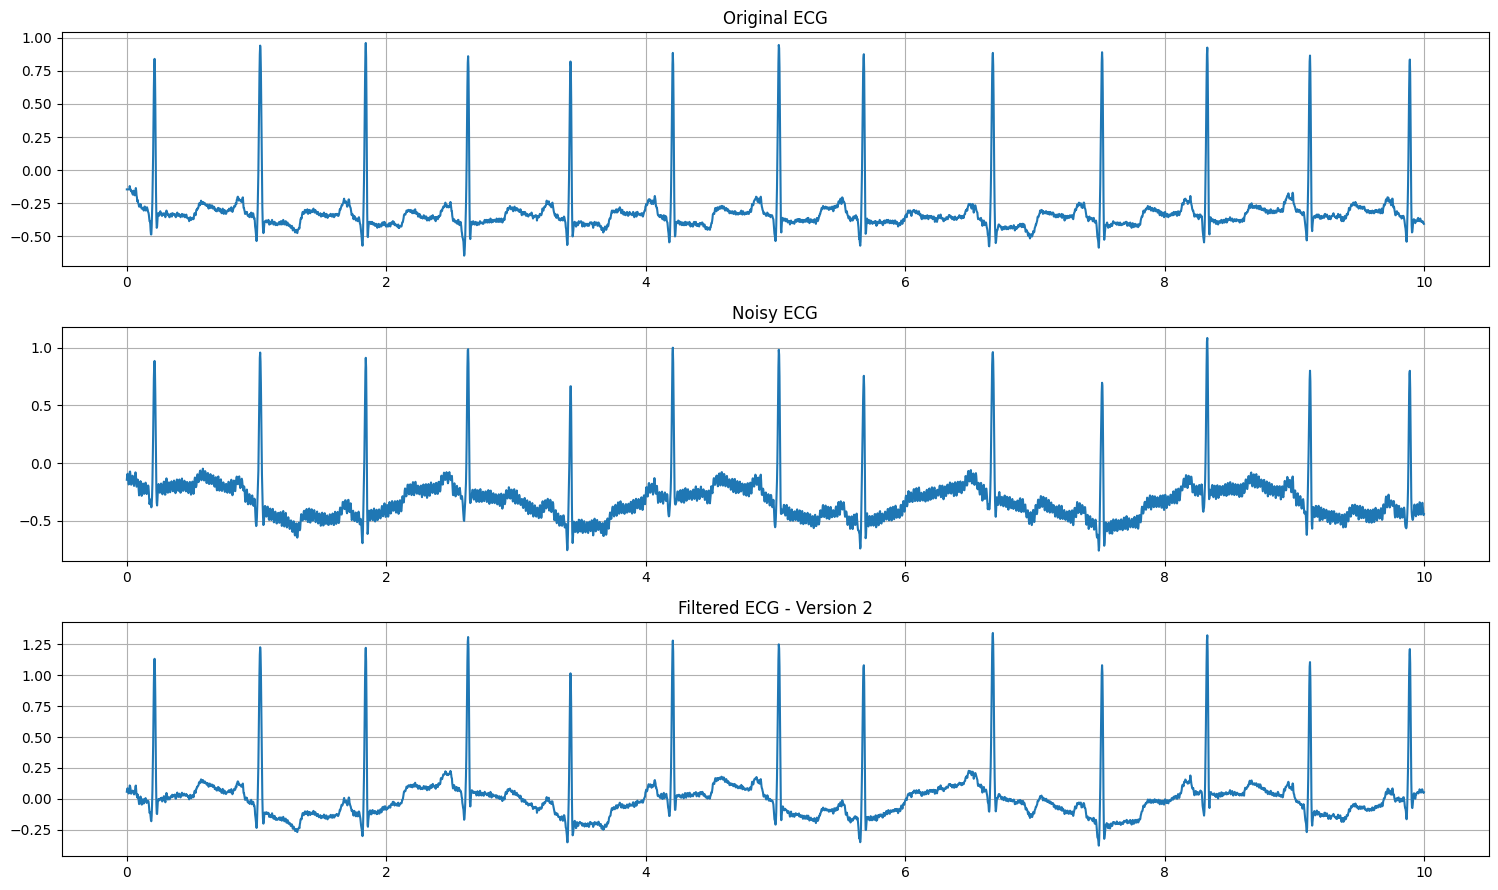

In [14]:
plt.figure(figsize=(15, 9))

plt.subplot(3, 1, 1)
plt.plot(t, ecg_10sec)
plt.title("Original ECG")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, noisy_ecg)
plt.title("Noisy ECG")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, filtered_ecg_v2)
plt.title("Filtered ECG - Version 2")
plt.grid()

plt.tight_layout()
plt.show()

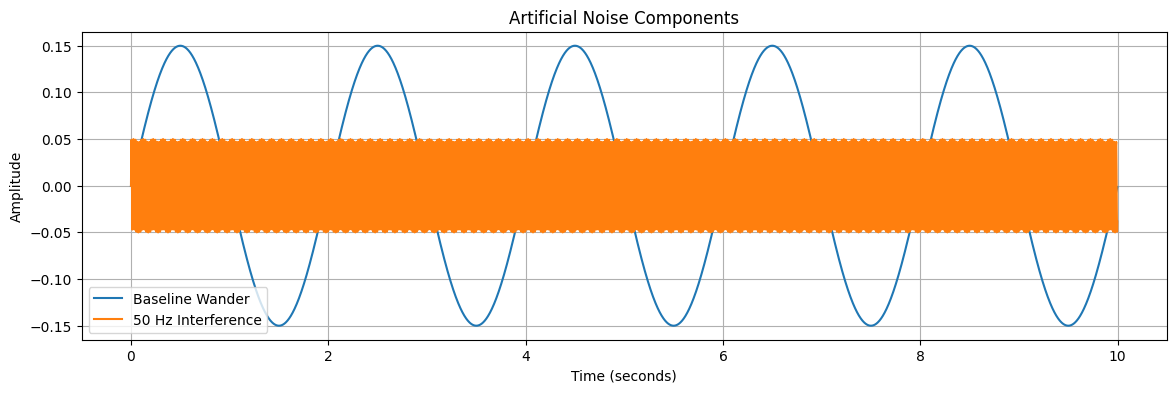

In [15]:
plt.figure(figsize=(14, 4))

plt.plot(t, baseline_noise, label="Baseline Wander")
plt.plot(t, powerline_noise, label="50 Hz Interference")

plt.title("Artificial Noise Components")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()
plt.show()

In [16]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

# Design filters
hp = butter(2, 0.5, btype='highpass', fs=fs, output='sos')
b, a = iirnotch(50, 30, fs)

# Apply same filters to clean ECG
clean_reference = sosfiltfilt(hp, ecg_10sec)
clean_reference = filtfilt(b, a, clean_reference)

# Apply same filters to noisy ECG
filtered_reference = sosfiltfilt(hp, noisy_ecg)
filtered_reference = filtfilt(b, a, filtered_reference)

# Estimate remaining noise after filtering
remaining_noise = filtered_reference - clean_reference

# Calculate input SNR
input_noise = noisy_ecg - ecg_10sec

snr_input = 10 * np.log10(
    np.mean(ecg_10sec**2) / np.mean(input_noise**2)
)

# Calculate output SNR
snr_output = 10 * np.log10(
    np.mean(clean_reference**2) /
    np.mean(remaining_noise**2)
)

print("Input SNR:", snr_input, "dB")
print("Output SNR:", snr_output, "dB")
print("SNR Improvement:", snr_output - snr_input, "dB")

Input SNR: 10.214411168493431 dB
Output SNR: 10.397800088338451 dB
SNR Improvement: 0.18338891984502048 dB


In [17]:
from scipy.signal import butter, sosfiltfilt

# Band-pass filter: 0.5 Hz to 40 Hz
bandpass = butter(
    4, [0.5, 40],
    btype='bandpass',
    fs=fs,
    output='sos'
)

# Apply band-pass filter to clean and noisy ECG
clean_bandpass = sosfiltfilt(bandpass, ecg_10sec)
noisy_bandpass = sosfiltfilt(bandpass, noisy_ecg)

# Calculate remaining noise
remaining_noise_bp = noisy_bandpass - clean_bandpass

# Calculate SNR
snr_before = 10 * np.log10(
    np.mean(ecg_10sec**2) /
    np.mean((noisy_ecg - ecg_10sec)**2)
)

snr_after_bp = 10 * np.log10(
    np.mean(clean_bandpass**2) /
    np.mean(remaining_noise_bp**2)
)

print("Input SNR:", snr_before, "dB")
print("Band-pass Output SNR:", snr_after_bp, "dB")
print("SNR Improvement:", snr_after_bp - snr_before, "dB")

Input SNR: 10.214411168493431 dB
Band-pass Output SNR: 10.434408835110867 dB
SNR Improvement: 0.21999766661743614 dB


In [18]:
from scipy.ndimage import uniform_filter1d

# Moving average filter
window_size = 5

clean_ma = uniform_filter1d(ecg_10sec, size=window_size)
noisy_ma = uniform_filter1d(noisy_ecg, size=window_size)

# Calculate remaining noise
remaining_noise_ma = noisy_ma - clean_ma

# Calculate SNR
snr_after_ma = 10 * np.log10(
    np.mean(clean_ma**2) /
    np.mean(remaining_noise_ma**2)
)

print("Input SNR:", snr_before, "dB")
print("Moving Average Output SNR:", snr_after_ma, "dB")
print("SNR Improvement:", snr_after_ma - snr_before, "dB")

Input SNR: 10.214411168493431 dB
Moving Average Output SNR: 10.453788995030902 dB
SNR Improvement: 0.23937782653747064 dB


In [19]:
# Load expert annotations for record 100
annotation = wfdb.rdann('100', 'atr', pn_dir='mitdb')

# Get annotation positions and labels
ann_samples = annotation.sample
ann_symbols = annotation.symbol

# Show annotations within our first 10 seconds
for sample, symbol in zip(ann_samples, ann_symbols):
    if sample < samples:
        print(
            "Time:", round(sample / fs, 3), "seconds",
            "| Label:", symbol
        )

Time: 0.05 seconds | Label: +
Time: 0.214 seconds | Label: N
Time: 1.028 seconds | Label: N
Time: 1.839 seconds | Label: N
Time: 2.628 seconds | Label: N
Time: 3.419 seconds | Label: N
Time: 4.208 seconds | Label: N
Time: 5.025 seconds | Label: N
Time: 5.678 seconds | Label: A
Time: 6.672 seconds | Label: N
Time: 7.517 seconds | Label: N
Time: 8.328 seconds | Label: N
Time: 9.117 seconds | Label: N
Time: 9.889 seconds | Label: N


In [20]:
# Extract heartbeat segments around annotation points

before = int(0.25 * fs)  # 0.25 seconds before beat
after = int(0.45 * fs)   # 0.45 seconds after beat

beats = []
labels = []

for sample, symbol in zip(ann_samples, ann_symbols):

    # Keep only normal and atrial premature beats
    if symbol not in ['N', 'A']:
        continue

    start = sample - before
    end = sample + after

    # Avoid segments outside signal boundaries
    if start < 0 or end > len(ecg_signal):
        continue

    beat = ecg_signal[start:end]

    beats.append(beat)
    labels.append(symbol)

beats = np.array(beats)
labels = np.array(labels)

print("Heartbeat segmentation completed!")
print("Total heartbeat segments:", len(beats))
print("Samples per heartbeat:", beats.shape[1])
print("Labels:", labels)

Heartbeat segmentation completed!
Total heartbeat segments: 2270
Samples per heartbeat: 252
Labels: ['N' 'N' 'N' ... 'N' 'N' 'N']


In [21]:
unique_labels, counts = np.unique(
    labels,
    return_counts=True
)

print("Heartbeat Class Distribution:")

for label, count in zip(unique_labels, counts):
    print(label, ":", count)

print("Total beats:", len(labels))

Heartbeat Class Distribution:
A : 33
N : 2237
Total beats: 2270


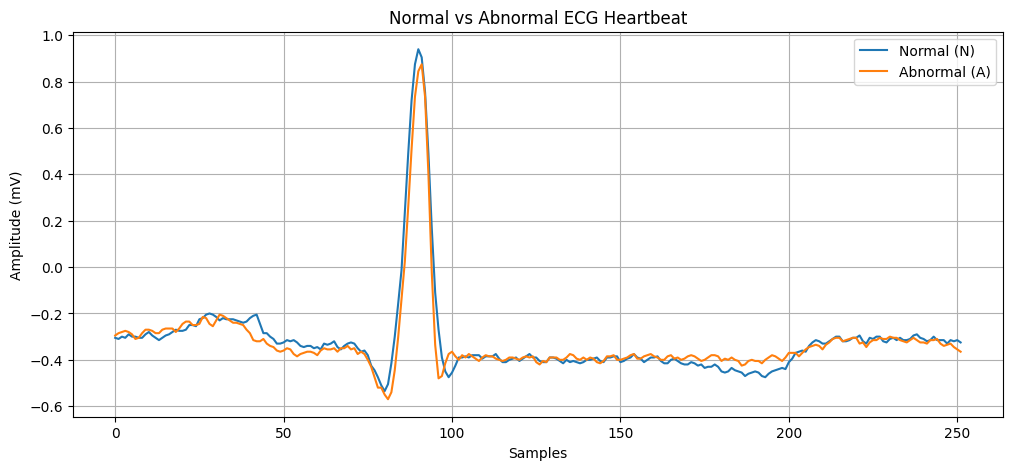

In [22]:
plt.figure(figsize=(12, 5))

# Find one normal and one abnormal beat
normal_index = np.where(labels == 'N')[0][0]
abnormal_index = np.where(labels == 'A')[0][0]

plt.plot(beats[normal_index], label='Normal (N)')
plt.plot(beats[abnormal_index], label='Abnormal (A)')

plt.title("Normal vs Abnormal ECG Heartbeat")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid()
plt.show()

In [23]:
import wfdb
import numpy as np

record_list = ['100', '101', '102', '103', '105']

all_beats = []
all_labels = []

before = int(0.25 * 360)
after = int(0.45 * 360)

for record_name in record_list:

    print("Processing record:", record_name)

    record = wfdb.rdrecord(record_name, pn_dir='mitdb')
    annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')

    ecg = record.p_signal[:, 0]

    for sample, symbol in zip(annotation.sample, annotation.symbol):

        if symbol not in ['N', 'A']:
            continue

        start = sample - before
        end = sample + after

        if start < 0 or end > len(ecg):
            continue

        beat = ecg[start:end]

        all_beats.append(beat)
        all_labels.append(symbol)

all_beats = np.array(all_beats)
all_labels = np.array(all_labels)

print("\nDataset preparation completed!")
print("Total heartbeats:", len(all_beats))
print("Heartbeat shape:", all_beats.shape)

Processing record: 100
Processing record: 101
Processing record: 102
Processing record: 103
Processing record: 105

Dataset preparation completed!
Total heartbeats: 8840
Heartbeat shape: (8840, 252)


In [24]:
unique_labels, counts = np.unique(
    all_labels,
    return_counts=True
)

print("Updated Class Distribution:")

for label, count in zip(unique_labels, counts):
    print(label, ":", count)

Updated Class Distribution:
A : 38
N : 8802


In [25]:
from collections import Counter

all_symbols = []

for record_name in record_list:

    annotation = wfdb.rdann(
        record_name,
        'atr',
        pn_dir='mitdb'
    )

    all_symbols.extend(annotation.symbol)

symbol_counts = Counter(all_symbols)

print("All annotation symbols and their counts:\n")

for symbol, count in sorted(symbol_counts.items()):
    print(repr(symbol), ":", count)

All annotation symbols and their counts:

'+' : 9
'/' : 2028
'A' : 38
'N' : 8806
'Q' : 7
'V' : 46
'f' : 56
'|' : 34
'~' : 98


In [26]:
import wfdb
import numpy as np
from collections import Counter

# Heartbeat classes selected for our experiment
selected_classes = ['N', 'A', 'V', 'f']

all_beats_4class = []
all_labels_4class = []
record_ids = []

for record_name in record_list:

    print("Processing:", record_name)

    record = wfdb.rdrecord(record_name, pn_dir='mitdb')
    annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')

    ecg = record.p_signal[:, 0]
    fs_local = record.fs

    before = int(0.25 * fs_local)
    after = int(0.45 * fs_local)

    for sample, symbol in zip(annotation.sample, annotation.symbol):

        if symbol not in selected_classes:
            continue

        start = sample - before
        end = sample + after

        if start < 0 or end > len(ecg):
            continue

        beat = ecg[start:end]

        all_beats_4class.append(beat)
        all_labels_4class.append(symbol)
        record_ids.append(record_name)

all_beats_4class = np.array(all_beats_4class)
all_labels_4class = np.array(all_labels_4class)
record_ids = np.array(record_ids)

print("\nFour-class dataset prepared!")
print("Dataset shape:", all_beats_4class.shape)

print("\nClass distribution:")
for label, count in sorted(Counter(all_labels_4class).items()):
    print(label, ":", count)

print("\nTotal heartbeat segments:", len(all_labels_4class))

Processing: 100
Processing: 101
Processing: 102
Processing: 103
Processing: 105

Four-class dataset prepared!
Dataset shape: (8942, 252)

Class distribution:
A : 38
N : 8802
V : 46
f : 56

Total heartbeat segments: 8942


In [27]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# First split: 80% training, 20% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        all_beats_4class,
        all_labels_4class,
        groups=record_ids
    )
)

print("Training records:", np.unique(record_ids[train_idx]))
print("Temporary records:", np.unique(record_ids[temp_idx]))

Training records: ['100' '102' '103' '105']
Temporary records: ['101']


In [28]:
from collections import Counter

print("TRAINING CLASS DISTRIBUTION")

for label, count in sorted(
    Counter(all_labels_4class[train_idx]).items()
):
    print(label, ":", count)

print("\nTEMPORARY CLASS DISTRIBUTION")

for label, count in sorted(
    Counter(all_labels_4class[temp_idx]).items()
):
    print(label, ":", count)

TRAINING CLASS DISTRIBUTION
A : 35
N : 6943
V : 46
f : 56

TEMPORARY CLASS DISTRIBUTION
A : 3
N : 1859


In [29]:
print("CLASS DISTRIBUTION PER RECORD\n")

for record_name in record_list:

    print("\nRecord:", record_name)

    mask = record_ids == record_name

    record_labels = all_labels_4class[mask]

    unique, counts = np.unique(
        record_labels,
        return_counts=True
    )

    for label, count in zip(unique, counts):
        print(label, ":", count)

CLASS DISTRIBUTION PER RECORD


Record: 100
A : 33
N : 2237
V : 1

Record: 101
A : 3
N : 1859

Record: 102
N : 99
V : 4
f : 56

Record: 103
A : 2
N : 2081

Record: 105
N : 2526
V : 41


In [30]:
extra_records = [
    '106', '108', '109', '111',
    '112', '113', '114', '115'
]

for record_name in extra_records:

    print("Processing:", record_name)

    record = wfdb.rdrecord(record_name, pn_dir='mitdb')
    annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')

    ecg = record.p_signal[:, 0]
    fs_local = record.fs

    before = int(0.25 * fs_local)
    after = int(0.45 * fs_local)

    for sample, symbol in zip(annotation.sample, annotation.symbol):

        if symbol not in ['N', 'A', 'V', 'f']:
            continue

        start = sample - before
        end = sample + after

        if start < 0 or end > len(ecg):
            continue

        beat = ecg[start:end]

        all_beats_4class = np.vstack(
            [all_beats_4class, beat]
        )

        all_labels_4class = np.append(
            all_labels_4class, symbol
        )

        record_ids = np.append(
            record_ids, record_name
        )

print("\nExpanded dataset shape:", all_beats_4class.shape)
print("Total records:", len(np.unique(record_ids)))

Processing: 106
Processing: 108
Processing: 109
Processing: 111
Processing: 112
Processing: 113
Processing: 114
Processing: 115

Expanded dataset shape: (20918, 252)
Total records: 13


In [31]:
print("Records currently in dataset:")
print(np.unique(record_ids))

print("Current dataset shape:")
print(all_beats_4class.shape)

Records currently in dataset:
['100' '101' '102' '103' '105' '106' '108' '109' '111' '112' '113' '114'
 '115']
Current dataset shape:
(20918, 252)


In [32]:
from collections import Counter

# Update record list
record_list = sorted(np.unique(record_ids).tolist())

print("Total records:", len(record_list))
print("Records:", record_list)

print("\nUpdated class distribution:")

for label, count in sorted(Counter(all_labels_4class).items()):
    percentage = count / len(all_labels_4class) * 100
    print(label, ":", count, f"({percentage:.2f}%)")

print("\nTotal heartbeats:", len(all_labels_4class))

Total records: 13
Records: ['100', '101', '102', '103', '105', '106', '108', '109', '111', '112', '113', '114', '115']

Updated class distribution:
A : 54 (0.26%)
N : 20143 (96.30%)
V : 665 (3.18%)
f : 56 (0.27%)

Total heartbeats: 20918


In [33]:
print("CLASS DISTRIBUTION PER RECORD\n")

for record_name in record_list:

    mask = record_ids == record_name
    record_labels = all_labels_4class[mask]

    print("\nRecord:", record_name)

    unique, counts = np.unique(
        record_labels,
        return_counts=True
    )

    for label, count in zip(unique, counts):
        print(label, ":", count)

CLASS DISTRIBUTION PER RECORD


Record: 100
A : 33
N : 2237
V : 1

Record: 101
A : 3
N : 1859

Record: 102
N : 99
V : 4
f : 56

Record: 103
A : 2
N : 2081

Record: 105
N : 2526
V : 41

Record: 106
N : 1507
V : 520

Record: 108
A : 4
N : 1738
V : 17

Record: 109
V : 38

Record: 111
V : 1

Record: 112
A : 2
N : 2536

Record: 113
N : 1788

Record: 114
A : 10
N : 1820
V : 43

Record: 115
N : 1952


In [34]:
# Get all available MIT-BIH record names
all_mit_records = wfdb.get_record_list('mitdb')

existing_records = set(record_list)

print("Scanning remaining MIT-BIH records...\n")

for record_name in all_mit_records:

    if record_name in existing_records:
        continue

    try:
        annotation = wfdb.rdann(
            record_name,
            'atr',
            pn_dir='mitdb'
        )

        symbols = annotation.symbol

        counts = {
            label: symbols.count(label)
            for label in ['A', 'N', 'V', 'f']
        }

        if counts['A'] > 0 or counts['V'] > 0 or counts['f'] > 0:
            print(
                record_name,
                "| A:", counts['A'],
                "| N:", counts['N'],
                "| V:", counts['V'],
                "| f:", counts['f']
            )

    except Exception as e:
        print("Could not load:", record_name)

Scanning remaining MIT-BIH records...

104 | A: 0 | N: 163 | V: 2 | f: 666
107 | A: 0 | N: 0 | V: 59 | f: 0
116 | A: 1 | N: 2302 | V: 109 | f: 0
117 | A: 1 | N: 1534 | V: 0 | f: 0
118 | A: 96 | N: 0 | V: 16 | f: 0
119 | A: 0 | N: 1543 | V: 444 | f: 0
121 | A: 1 | N: 1861 | V: 1 | f: 0
123 | A: 0 | N: 1515 | V: 3 | f: 0
124 | A: 2 | N: 0 | V: 47 | f: 0
200 | A: 30 | N: 1743 | V: 826 | f: 0
201 | A: 30 | N: 1625 | V: 198 | f: 0
202 | A: 36 | N: 2061 | V: 19 | f: 0
203 | A: 0 | N: 2529 | V: 444 | f: 0
205 | A: 3 | N: 2571 | V: 71 | f: 0
207 | A: 107 | N: 0 | V: 105 | f: 0
208 | A: 0 | N: 1586 | V: 992 | f: 0
209 | A: 383 | N: 2621 | V: 1 | f: 0
210 | A: 0 | N: 2423 | V: 194 | f: 0
213 | A: 25 | N: 2641 | V: 220 | f: 0
214 | A: 0 | N: 0 | V: 256 | f: 0
215 | A: 3 | N: 3195 | V: 164 | f: 0
217 | A: 0 | N: 244 | V: 162 | f: 260
219 | A: 7 | N: 2082 | V: 64 | f: 0
220 | A: 94 | N: 1954 | V: 0 | f: 0
221 | A: 0 | N: 2031 | V: 396 | f: 0
222 | A: 208 | N: 2062 | V: 0 | f: 0
223 | A: 72 | N: 202

In [35]:

# Add records 104 and 217 without duplicating existing data

new_records = ['104', '217']
selected_classes = ['N', 'A', 'V', 'f']

existing_records = set(record_ids.astype(str))

new_beats = []
new_labels = []
new_record_ids = []

for record_name in new_records:

    if record_name in existing_records:
        print("Already added:", record_name)
        continue

    print("Loading record:", record_name)

    record = wfdb.rdrecord(record_name, pn_dir='mitdb')
    annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')

    ecg = record.p_signal[:, 0]
    fs_local = record.fs

    before = int(0.25 * fs_local)
    after = int(0.45 * fs_local)

    for sample, symbol in zip(annotation.sample, annotation.symbol):

        if symbol not in selected_classes:
            continue

        start = sample - before
        end = sample + after

        if start < 0 or end > len(ecg):
            continue

        new_beats.append(ecg[start:end])
        new_labels.append(symbol)
        new_record_ids.append(record_name)

# Append only the newly loaded data
if len(new_beats) > 0:
    all_beats_4class = np.concatenate(
        [all_beats_4class, np.array(new_beats)]
    )

    all_labels_4class = np.concatenate(
        [all_labels_4class, np.array(new_labels)]
    )

    record_ids = np.concatenate(
        [record_ids, np.array(new_record_ids)]
    )

print("\nUpdated dataset shape:", all_beats_4class.shape)

print("\nUpdated class distribution:")
unique, counts = np.unique(all_labels_4class, return_counts=True)

for label, count in zip(unique, counts):
    print(label, ":", count)

print("\nRecords included:")
print(np.unique(record_ids))


Loading record: 104
Loading record: 217

Updated dataset shape: (22415, 252)

Updated class distribution:
A : 54
N : 20550
V : 829
f : 982

Records included:
['100' '101' '102' '103' '104' '105' '106' '108' '109' '111' '112' '113'
 '114' '115' '217']


In [36]:
import pandas as pd

df = pd.DataFrame({
    'Record': record_ids,
    'Label': all_labels_4class
})

record_class_counts = pd.crosstab(
    df['Record'],
    df['Label']
)

print("Class distribution in each record:")
display(record_class_counts)

print("\nNumber of records containing each class:")
print((record_class_counts > 0).sum())

Class distribution in each record:


Label,A,N,V,f
Record,,,,
100,33,2237,1,0
101,3,1859,0,0
102,0,99,4,56
103,2,2081,0,0
104,0,163,2,666
105,0,2526,41,0
106,0,1507,520,0
108,4,1738,17,0
109,0,0,38,0



Number of records containing each class:
Label
A     6
N    13
V    10
f     3
dtype: int64


In [37]:
# Define record-wise groups
validation_records = ['100', '104']
test_records = ['112', '114', '217']

all_records = np.unique(record_ids)

train_records = [
    r for r in all_records
    if r not in validation_records + test_records
]

# Create masks
train_mask = np.isin(record_ids, train_records)
val_mask = np.isin(record_ids, validation_records)
test_mask = np.isin(record_ids, test_records)

# Split the dataset
X_train = all_beats_4class[train_mask]
y_train = all_labels_4class[train_mask]

X_val = all_beats_4class[val_mask]
y_val = all_labels_4class[val_mask]

X_test = all_beats_4class[test_mask]
y_test = all_labels_4class[test_mask]

# Display split information
print("Training records:", train_records)
print("Validation records:", validation_records)
print("Testing records:", test_records)

print("\nDataset shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nClass distribution:")
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(pd.Series(labels).value_counts().sort_index())

Training records: [np.str_('101'), np.str_('102'), np.str_('103'), np.str_('105'), np.str_('106'), np.str_('108'), np.str_('109'), np.str_('111'), np.str_('113'), np.str_('115')]
Validation records: ['100', '104']
Testing records: ['112', '114', '217']

Dataset shapes:
Training: (14236, 252)
Validation: (3102, 252)
Testing: (5077, 252)

Class distribution:

Training:
A        9
N    13550
V      621
f       56
Name: count, dtype: int64

Validation:
A      33
N    2400
V       3
f     666
Name: count, dtype: int64

Testing:
A      12
N    4600
V     205
f     260
Name: count, dtype: int64


In [110]:
train_records = [
    '100', '101', '103', '105', '106', '107',
    '108', '109', '111', '112', '117', '118',
    '119', '121', '122', '123', '124',
    '200', '201', '202', '203', '205', '207',
    '208', '209', '210', '212', '213', '214',
    '215', '217', '219', '220', '221', '222',
    '223', '228', '230', '231', '232', '233', '234'
]

validation_records = ['113', '114']

test_records = ['115', '116']

train_mask = np.isin(record_ids, train_records)
val_mask = np.isin(record_ids, validation_records)
test_mask = np.isin(record_ids, test_records)

X_train = all_beats_4class[train_mask]
y_train = all_labels_4class[train_mask]

X_val = all_beats_4class[val_mask]
y_val = all_labels_4class[val_mask]

X_test = all_beats_4class[test_mask]
y_test = all_labels_4class[test_mask]

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(pd.Series(labels).value_counts().sort_index())


Training:
A       44
N    14728
V      780
f      260
Name: count, dtype: int64

Validation:
A      10
N    3608
V      43
Name: count, dtype: int64

Testing:
N    1952
Name: count, dtype: int64


In [39]:
import wfdb
from collections import Counter

record_list = [
    '100', '101', '102', '103', '104', '105',
    '106', '108', '109', '111', '112', '113',
    '114', '217'
]

symbol_counts = Counter()

for record_name in record_list:
    annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')
    symbol_counts.update(annotation.symbol)

print("Available annotation symbols:")
for symbol, count in sorted(symbol_counts.items()):
    print(repr(symbol), ":", count)

Available annotation symbols:
'+' : 170
'/' : 4950
'A' : 54
'F' : 8
'J' : 2
'L' : 4615
'N' : 18605
'Q' : 25
'V' : 829
'a' : 6
'f' : 982
'j' : 1
'x' : 11
'|' : 44
'~' : 237


In [40]:
import wfdb
from collections import Counter

# AAMI class mapping
class_mapping = {
    'N': ['N', 'L', 'R', 'e', 'j'],
    'S': ['A', 'a', 'J', 'S'],
    'V': ['V', 'E'],
    'F': ['F'],
    'Q': ['/', 'f', 'Q']
}

class_counts = Counter()

for record_name in record_list:
    annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb')

    for symbol in annotation.symbol:
        for class_name, symbols in class_mapping.items():
            if symbol in symbols:
                class_counts[class_name] += 1
                break

print("AAMI CLASS DISTRIBUTION")
for class_name in ['N', 'S', 'V', 'F', 'Q']:
    print(class_name, ":", class_counts[class_name])

AAMI CLASS DISTRIBUTION
N : 23221
S : 62
V : 829
F : 8
Q : 5957


In [41]:

import wfdb
from collections import Counter

all_records = wfdb.get_record_list('mitdb')

class_mapping = {
    'N': ['N', 'L', 'R', 'e', 'j'],
    'S': ['A', 'a', 'J', 'S'],
    'V': ['V', 'E'],
    'F': ['F'],
    'Q': ['/', 'f', 'Q']
}

total_counts = Counter()
records_checked = 0

for record_name in all_records:
    try:
        annotation = wfdb.rdann(
            record_name, 'atr', pn_dir='mitdb'
        )

        for symbol in annotation.symbol:
            for class_name, symbols in class_mapping.items():
                if symbol in symbols:
                    total_counts[class_name] += 1
                    break

        records_checked += 1

    except Exception as e:
        print("Could not read:", record_name, e)

print("Records checked:", records_checked)
print("\nFull dataset class distribution:")

for class_name in ['N', 'S', 'V', 'F', 'Q']:
    print(class_name, ":", total_counts[class_name])


Records checked: 48

Full dataset class distribution:
N : 90631
S : 2781
V : 7236
F : 803
Q : 8043


In [42]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

# Load ECG record
record = wfdb.rdrecord('100', pn_dir='mitdb')

fs = record.fs

# Use 60 seconds of ECG
duration = 60
clean_ecg = record.p_signal[:duration * fs, 0]

t = np.arange(len(clean_ecg)) / fs

# Generate artificial noise
rng = np.random.default_rng(42)

# Baseline wander
baseline_noise = 0.15 * np.sin(2 * np.pi * 0.5 * t)

# 50 Hz power-line interference
powerline_noise = 0.05 * np.sin(2 * np.pi * 50 * t)

# Simulated muscle-like noise (band-limited noise)
white_noise = rng.normal(0, 1, len(clean_ecg))

emg_filter = butter(
    4, [20, 100],
    btype='bandpass',
    fs=fs,
    output='sos'
)

emg_noise = sosfiltfilt(emg_filter, white_noise)
emg_noise = emg_noise / (np.std(emg_noise) + 1e-8) * 0.05

# Combined noise
combined_noise = (
    baseline_noise +
    powerline_noise +
    emg_noise
)

noisy_ecg = clean_ecg + combined_noise

print("ECG signal prepared successfully!")
print("Sampling frequency:", fs)
print("Total samples:", len(clean_ecg))
print("Duration:", duration, "seconds")


ECG signal prepared successfully!
Sampling frequency: 360
Total samples: 21600
Duration: 60 seconds


In [43]:

# Method 1: High-pass + Notch filter

highpass = butter(
    2, 0.5,
    btype='highpass',
    fs=fs,
    output='sos'
)

b_notch, a_notch = iirnotch(50, 30, fs=fs)

highpass_output = sosfiltfilt(highpass, noisy_ecg)

method1 = filtfilt(
    b_notch, a_notch,
    highpass_output
)


# Method 2: Band-pass filter

bandpass = butter(
    4, [0.5, 40],
    btype='bandpass',
    fs=fs,
    output='sos'
)

method2 = sosfiltfilt(bandpass, noisy_ecg)


# Method 3: Band-pass + Notch filter

bandpass_output = sosfiltfilt(bandpass, noisy_ecg)

method3 = filtfilt(
    b_notch, a_notch,
    bandpass_output
)


# Method 4: Moving average filter

from scipy.ndimage import uniform_filter1d

method4 = uniform_filter1d(
    noisy_ecg,
    size=5
)

print("All filtering methods completed!")


All filtering methods completed!


In [44]:

def calculate_metrics(reference, noisy, filtered):

    # Input noise
    input_error = noisy - reference

    # Output error
    output_error = filtered - reference

    # Input SNR
    input_snr = 10 * np.log10(
        np.mean(reference ** 2) /
        (np.mean(input_error ** 2) + 1e-12)
    )

    # Output SNR
    output_snr = 10 * np.log10(
        np.mean(reference ** 2) /
        (np.mean(output_error ** 2) + 1e-12)
    )

    # SNR improvement
    improvement = output_snr - input_snr

    # RMSE
    rmse = np.sqrt(np.mean(output_error ** 2))

    # MSE
    mse = np.mean(output_error ** 2)

    # Percentage Root Mean Square Difference
    prd = (
        np.sqrt(np.sum(output_error ** 2)) /
        (np.sqrt(np.sum(reference ** 2)) + 1e-12)
    ) * 100

    return input_snr, output_snr, improvement, rmse, mse, prd


methods = {
    "High-pass + Notch": method1,
    "Band-pass": method2,
    "Band-pass + Notch": method3,
    "Moving Average": method4
}

results = []

for name, output in methods.items():

    metrics = calculate_metrics(
        clean_ecg,
        noisy_ecg,
        output
    )

    results.append([name, *metrics])


results_df = pd.DataFrame(
    results,
    columns=[
        "Method",
        "Input SNR (dB)",
        "Output SNR (dB)",
        "SNR Improvement (dB)",
        "RMSE",
        "MSE",
        "PRD (%)"
    ]
)

print(results_df.to_string(index=False))


           Method  Input SNR (dB)  Output SNR (dB)  SNR Improvement (dB)     RMSE      MSE   PRD (%)
High-pass + Notch        9.812433         0.779021             -9.033412 0.346885 0.120330 91.421627
        Band-pass        9.812433         0.834842             -8.977592 0.344663 0.118793 90.835984
Band-pass + Notch        9.812433         0.835291             -8.977143 0.344646 0.118781 90.831286
   Moving Average        9.812433        10.645878              0.833445 0.111389 0.012408 29.356623


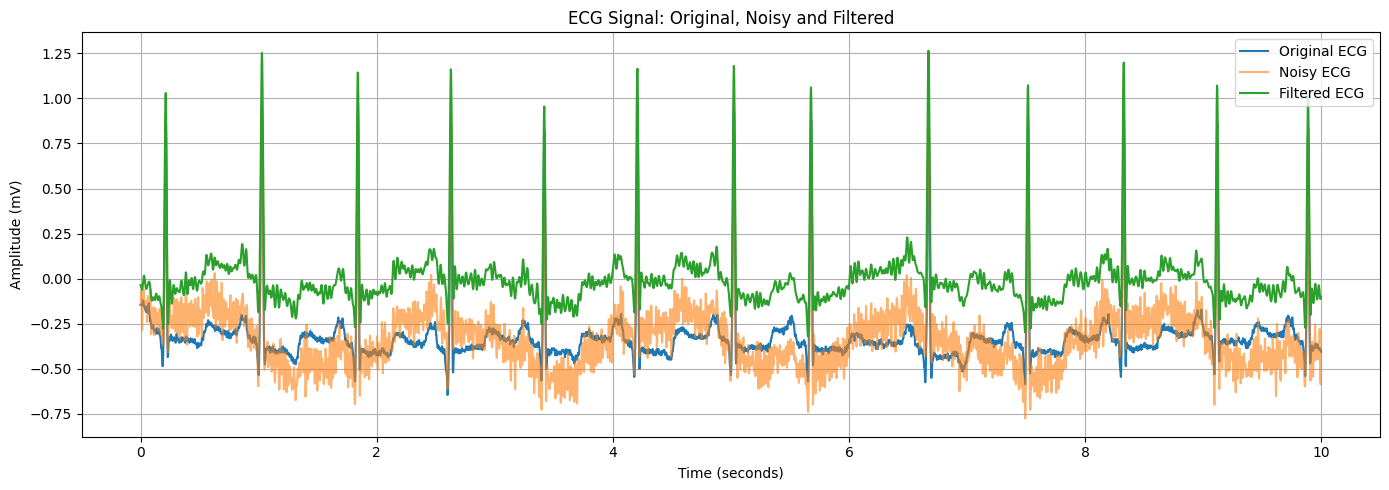

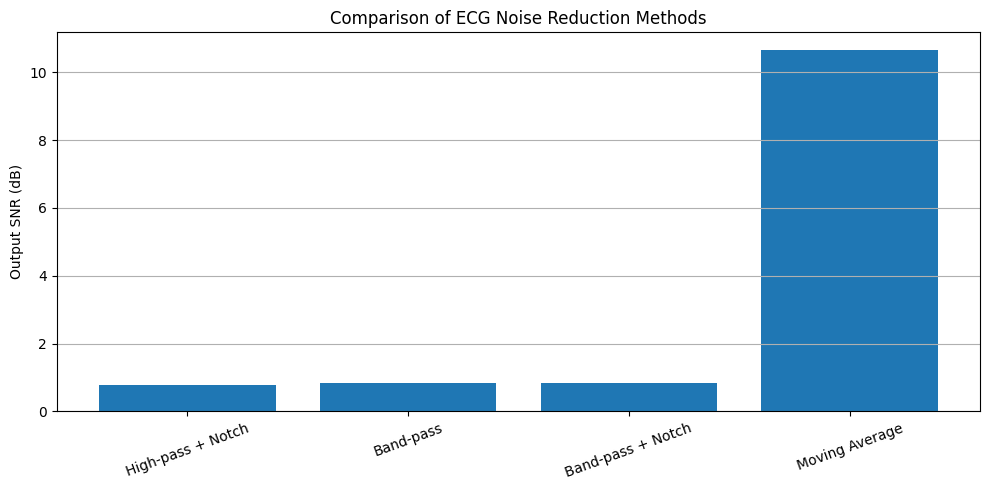

In [45]:

plt.figure(figsize=(14, 5))

plt.plot(t[:3600], clean_ecg[:3600],
         label="Original ECG")

plt.plot(t[:3600], noisy_ecg[:3600],
         label="Noisy ECG", alpha=0.6)

plt.plot(t[:3600], method3[:3600],
         label="Filtered ECG")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("ECG Signal: Original, Noisy and Filtered")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


# SNR comparison

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Method"],
    results_df["Output SNR (dB)"]
)

plt.ylabel("Output SNR (dB)")
plt.title("Comparison of ECG Noise Reduction Methods")
plt.xticks(rotation=20)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [46]:
def calculate_corrected_metrics(reference, noisy, filtered):

    # Input noise error
    input_error = noisy - reference

    # Correct constant DC offset between filtered and reference
    offset = np.mean(filtered - reference)
    aligned_filtered = filtered - offset

    # Output error after alignment
    output_error = aligned_filtered - reference

    # Input SNR
    input_snr = 10 * np.log10(
        np.mean(reference ** 2) /
        (np.mean(input_error ** 2) + 1e-12)
    )

    # Output SNR
    output_snr = 10 * np.log10(
        np.mean(reference ** 2) /
        (np.mean(output_error ** 2) + 1e-12)
    )

    improvement = output_snr - input_snr

    rmse = np.sqrt(np.mean(output_error ** 2))
    mse = np.mean(output_error ** 2)

    prd = (
        np.sqrt(np.sum(output_error ** 2)) /
        (np.sqrt(np.sum(reference ** 2)) + 1e-12)
    ) * 100

    return input_snr, output_snr, improvement, rmse, mse, prd


corrected_results = []

for name, output in methods.items():

    metrics = calculate_corrected_metrics(
        clean_ecg,
        noisy_ecg,
        output
    )

    corrected_results.append([name, *metrics])


corrected_df = pd.DataFrame(
    corrected_results,
    columns=[
        "Method",
        "Input SNR (dB)",
        "Output SNR (dB)",
        "SNR Improvement (dB)",
        "RMSE",
        "MSE",
        "PRD (%)"
    ]
)

print(corrected_df.to_string(index=False))

           Method  Input SNR (dB)  Output SNR (dB)  SNR Improvement (dB)     RMSE      MSE   PRD (%)
High-pass + Notch        9.812433        13.082937              3.270503 0.084138 0.007079 22.174466
        Band-pass        9.812433        14.062036              4.249603 0.075168 0.005650 19.810625
Band-pass + Notch        9.812433        14.071425              4.258992 0.075087 0.005638 19.789223
   Moving Average        9.812433        10.645878              0.833445 0.111389 0.012408 29.356623


In [47]:

from scipy.signal import find_peaks
import wfdb
import numpy as np
import pandas as pd

# Load expert ECG beat annotations for record 100
annotation = wfdb.rdann('100', 'atr', pn_dir='mitdb')

# Keep beat annotations within the first 60 seconds
beat_symbols = set("NLRBAaJSVrFejnE/fQ")

reference_peaks = np.array([
    sample
    for sample, symbol in zip(
        annotation.sample, annotation.symbol
    )
    if symbol in beat_symbols and sample < len(clean_ecg)
])

# Detect R-peaks in a signal
def detect_r_peaks(signal, fs):

    min_distance = int(0.25 * fs)
    prominence = 0.5 * np.std(signal)

    peaks, _ = find_peaks(
        signal,
        distance=min_distance,
        prominence=prominence
    )

    return peaks


# Evaluate detected peaks against reference annotations
def evaluate_r_peaks(reference, detected, tolerance):

    matched = set()

    for detected_peak in detected:

        differences = np.abs(reference - detected_peak)

        possible_matches = np.where(
            differences <= tolerance
        )[0]

        possible_matches = [
            i for i in possible_matches if i not in matched
        ]

        if possible_matches:
            best_match = min(
                possible_matches,
                key=lambda i: differences[i]
            )
            matched.add(best_match)

    true_positive = len(matched)
    false_positive = len(detected) - true_positive
    false_negative = len(reference) - true_positive

    sensitivity = (
        true_positive / (true_positive + false_negative + 1e-12)
    ) * 100

    precision = (
        true_positive / (true_positive + false_positive + 1e-12)
    ) * 100

    f1_score = (
        2 * sensitivity * precision /
        (sensitivity + precision + 1e-12)
    )

    return sensitivity, precision, f1_score


# Signals to evaluate
signals = {
    "Original ECG": clean_ecg,
    "Noisy ECG": noisy_ecg,
    "High-pass + Notch": method1,
    "Band-pass": method2,
    "Band-pass + Notch": method3,
    "Moving Average": method4
}

results = []

# Allow a detection error of 100 milliseconds
tolerance = int(0.05 * fs)

for name, signal in signals.items():

    detected_peaks = detect_r_peaks(signal, fs)

    sensitivity, precision, f1 = evaluate_r_peaks(
        reference_peaks,
        detected_peaks,
        tolerance
    )

    results.append([
        name,
        len(detected_peaks),
        sensitivity,
        precision,
        f1
    ])

rpeak_df = pd.DataFrame(
    results,
    columns=[
        "Method",
        "Detected R-peaks",
        "Sensitivity (%)",
        "Precision (%)",
        "F1-score (%)"
    ]
)

print("Reference R-peaks:", len(reference_peaks))
print(rpeak_df.to_string(index=False))


Reference R-peaks: 74
           Method  Detected R-peaks  Sensitivity (%)  Precision (%)  F1-score (%)
     Original ECG                92            100.0      80.434783     89.156627
        Noisy ECG               161            100.0      45.962733     62.978723
High-pass + Notch               154            100.0      48.051948     64.912281
        Band-pass               140            100.0      52.857143     69.158879
Band-pass + Notch               139            100.0      53.237410     69.483568
   Moving Average               136            100.0      54.411765     70.476190


In [48]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("Environment ready for ML model development!")


TensorFlow version: 2.21.0
NumPy version: 2.4.6
Environment ready for ML model development!


In [116]:

import wfdb
import numpy as np
from scipy.signal import butter, sosfiltfilt

# ECG settings
fs = 360
window_size = 1800
stride = 900
max_windows_per_record = 150

# Dataset split
train_records = [
    '100', '101', '103', '105', '106', '107',
    '108', '109', '111', '112', '117', '118',
    '119', '121', '122', '123', '124',
    '200', '201', '202', '203', '205', '207',
    '208', '209', '210', '212', '213', '214',
    '215', '217', '219', '220', '221', '222',
    '223', '228', '230', '231', '232', '233', '234'
]

val_records = ['113', '114']
test_records = ['115', '116']

# Reproducible random generator
rng = np.random.default_rng(42)

# EMG noise filter
emg_sos = butter(
    4, [20, 100],
    btype='bandpass',
    fs=fs,
    output='sos'
)

def create_noisy_signal(clean_signal):

    t = np.arange(len(clean_signal)) / fs

    baseline = 0.15 * np.sin(2 * np.pi * 0.5 * t)
    powerline = 0.05 * np.sin(2 * np.pi * 50 * t)

    white_noise = rng.normal(0, 1, len(clean_signal))

    emg = sosfiltfilt(emg_sos, white_noise)
    emg = emg / (np.std(emg) + 1e-8) * 0.05

    return clean_signal + baseline + powerline + emg


def prepare_dataset(record_ids):

    clean_windows = []
    noisy_windows = []

    for record_id in record_ids:

        print("Processing record:", record_id)

        record = wfdb.rdrecord(
            record_id,
            pn_dir='mitdb'
        )

        if record.fs != fs:
            raise ValueError(
                f"Unexpected sampling rate in record {record_id}"
            )

        # Select the MLII channel consistently
        if "MLII" not in record.sig_name:
            print(f"Skipping record {record_id}: MLII not available")
            continue

        lead_index = record.sig_name.index("MLII")

        signal = record.p_signal[:, lead_index].astype(np.float32)

        starts = np.arange(
            0,
            len(signal) - window_size + 1,
            stride
        )

        if len(starts) > max_windows_per_record:
            starts = np.sort(
                rng.choice(
                    starts,
                    size=max_windows_per_record,
                    replace=False
                )
            )

        for start in starts:

            clean = signal[start:start + window_size].copy()

            mean = np.mean(clean)
            std = np.std(clean) + 1e-8

            clean_normalized = (clean - mean) / std

            noisy = create_noisy_signal(clean_normalized)

            clean_windows.append(clean_normalized)
            noisy_windows.append(noisy)

    clean_windows = np.asarray(
        clean_windows, dtype=np.float32
    )[..., np.newaxis]

    noisy_windows = np.asarray(
        noisy_windows, dtype=np.float32
    )[..., np.newaxis]

    return noisy_windows, clean_windows


# Generate datasets
train_noisy, train_clean = prepare_dataset(train_records)

val_noisy, val_clean = prepare_dataset(val_records)

test_noisy, test_clean = prepare_dataset(test_records)


print("\nDATA PREPARATION COMPLETED")

print("Training noisy:", train_noisy.shape)
print("Training clean:", train_clean.shape)

print("Validation noisy:", val_noisy.shape)
print("Validation clean:", val_clean.shape)

print("Testing noisy:", test_noisy.shape)
print("Testing clean:", test_clean.shape)


Processing record: 100
Processing record: 101
Processing record: 103
Processing record: 105
Processing record: 106
Processing record: 107
Processing record: 108
Processing record: 109
Processing record: 111
Processing record: 112
Processing record: 117
Processing record: 118
Processing record: 119
Processing record: 121
Processing record: 122
Processing record: 123
Processing record: 124
Processing record: 200
Processing record: 201
Processing record: 202
Processing record: 203
Processing record: 205
Processing record: 207
Processing record: 208
Processing record: 209
Processing record: 210
Processing record: 212
Processing record: 213
Processing record: 214
Processing record: 215
Processing record: 217
Processing record: 219
Processing record: 220
Processing record: 221
Processing record: 222
Processing record: 223
Processing record: 228
Processing record: 230
Processing record: 231
Processing record: 232
Processing record: 233
Processing record: 234
Processing record: 113
Processing 

In [50]:
%whos

Variable                      Type                 Data/Info
------------------------------------------------------------
Counter                       type                 <class 'collections.Counter'>
GroupShuffleSplit             ABCMeta              <class 'sklearn.model_sel<...>split.GroupShuffleSplit'>
X_test                        ndarray              5077x252: 1279404 elems, type `float64`, 10235232 bytes (9.761077880859375 Mb)
X_train                       ndarray              14555x252: 3667860 elems, type `float64`, 29342880 bytes (27.983551025390625 Mb)
X_val                         ndarray              831x252: 209412 elems, type `float64`, 1675296 bytes (1.597686767578125 Mb)
a                             ndarray              3: 3 elems, type `float64`, 24 bytes
a_notch                       ndarray              3: 3 elems, type `float64`, 24 bytes
abnormal_index                int64                6
after                         int                  162
all_beats        

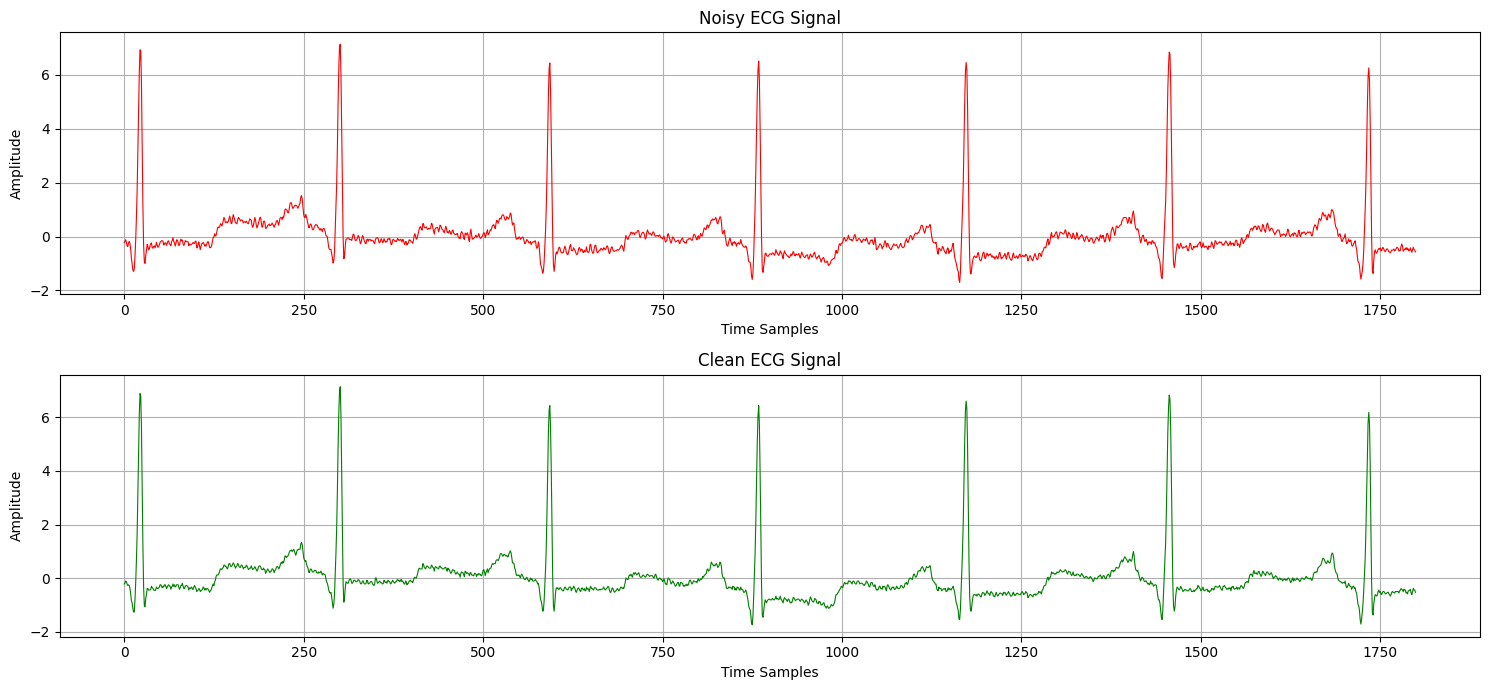

In [51]:

import matplotlib.pyplot as plt
import numpy as np

# Select one ECG sample
sample_index = 0

# Extract noisy and clean ECG signals
noisy_signal = train_noisy[sample_index].squeeze()
clean_signal = train_clean[sample_index].squeeze()

# Plot the signals
plt.figure(figsize=(15, 7))

plt.subplot(2, 1, 1)
plt.plot(noisy_signal, color='red', linewidth=0.8)
plt.title("Noisy ECG Signal")
plt.xlabel("Time Samples")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(clean_signal, color='green', linewidth=0.8)
plt.title("Clean ECG Signal")
plt.xlabel("Time Samples")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()


In [117]:

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    UpSampling1D, BatchNormalization,
    Activation
)
from tensorflow.keras.optimizers import Adam

# Input layer
input_signal = Input(shape=(1800, 1))

# Encoder
x = Conv1D(32, 7, padding='same')(input_signal)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling1D(2, padding='same')(x)

x = Conv1D(64, 7, padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = MaxPooling1D(2, padding='same')(x)

x = Conv1D(128, 7, padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
encoded = MaxPooling1D(2, padding='same')(x)

# Decoder
x = Conv1D(128, 7, padding='same', activation='relu')(encoded)
x = UpSampling1D(2)(x)

x = Conv1D(64, 7, padding='same', activation='relu')(x)
x = UpSampling1D(2)(x)

x = Conv1D(32, 7, padding='same', activation='relu')(x)
x = UpSampling1D(2)(x)

# Output layer
decoded = Conv1D(1, 7, padding='same', activation='linear')(x)

# Create autoencoder model
autoencoder = Model(input_signal, decoded)

# Compile model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Display model architecture
autoencoder.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1800, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 1800, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1800, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1800, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 900, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 900, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 900, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 900, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 450, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 450, 128)       │        57,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 450, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 450, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 225, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 225, 128)       │       114,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_3 (UpSampling1D)  │ (None, 450, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 450, 64)        │        57,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_4 (UpSampling1D)  │ (None, 900, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ (None, 900, 32)        │        14,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_5 (UpSampling1D)  │ (None, 1800, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 1800, 1)        │           225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259,841 (1015.00 KB)

 Trainable params: 259,393 (1013.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [119]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Define callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_ecg_denoising_model.keras',
    monitor='val_loss',
    save_best_only=True
)

# Train the autoencoder
history = autoencoder.fit(
    train_noisy,
    train_clean,
    epochs=30,
    batch_size=32,
    validation_data=(val_noisy, val_clean),
    callbacks=[early_stop, checkpoint],
    verbose=1
)


Epoch 1/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 85s 432ms/step - loss: 0.0125 - mae: 0.0918 - val_loss: 0.0139 - val_mae: 0.0959
Epoch 2/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 141s 429ms/step - loss: 0.0123 - mae: 0.0912 - val_loss: 0.0143 - val_mae: 0.0974
Epoch 3/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 147s 454ms/step - loss: 0.0121 - mae: 0.0906 - val_loss: 0.0140 - val_mae: 0.0968
Epoch 4/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 137s 430ms/step - loss: 0.0120 - mae: 0.0903 - val_loss: 0.0138 - val_mae: 0.0965
Epoch 5/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 85s 431ms/step - loss: 0.0120 - mae: 0.0901 - val_loss: 0.0129 - val_mae: 0.0941
Epoch 6/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 142s 430ms/step - loss: 0.0119 - mae: 0.0899 - val_loss: 0.0126 - val_mae: 0.0932
Epoch 7/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 84s 426ms/step - loss: 0.0118 - mae: 0.0895 - val_loss: 0.0126 - val_mae: 0.0926
Epoch 8/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 145s 441ms/step - loss: 0.0117 - mae: 0.0892 - val_loss: 0.0128 - val_mae: 0.0933
Epoch 9/30
197/197 ━━━━━━━━

In [120]:
from tensorflow.keras.models import load_model

best_model = load_model('best_ecg_denoising_model.keras')

val_predictions = best_model.predict(
    val_noisy,
    verbose=1
)

print("Prediction shape:", val_predictions.shape)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step
Prediction shape: (300, 1800, 1)


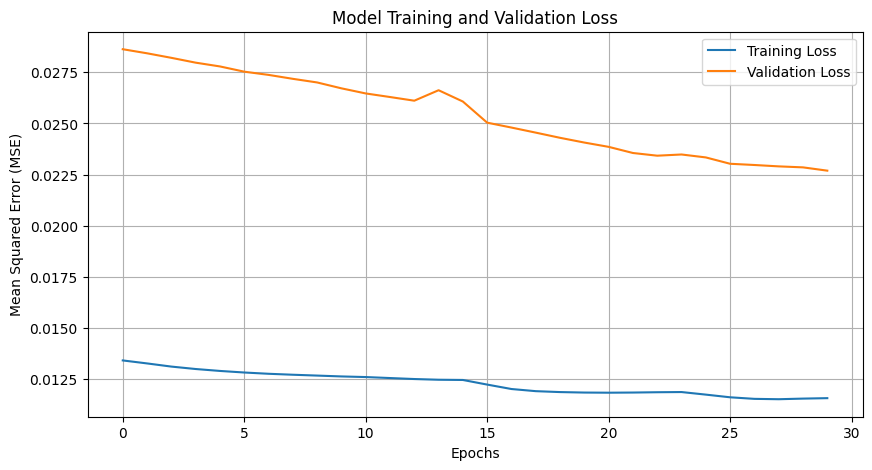

In [55]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')

plt.legend()
plt.grid(True)
plt.show()


In [56]:

# Generate denoised ECG signals
denoised_signals = autoencoder.predict(test_noisy)

print("Denoising completed successfully!")

print("Test noisy shape:", test_noisy.shape)
print("Test clean shape:", test_clean.shape)
print("Denoised output shape:", denoised_signals.shape)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step
Denoising completed successfully!
Test noisy shape: (300, 1800, 1)
Test clean shape: (300, 1800, 1)
Denoised output shape: (300, 1800, 1)


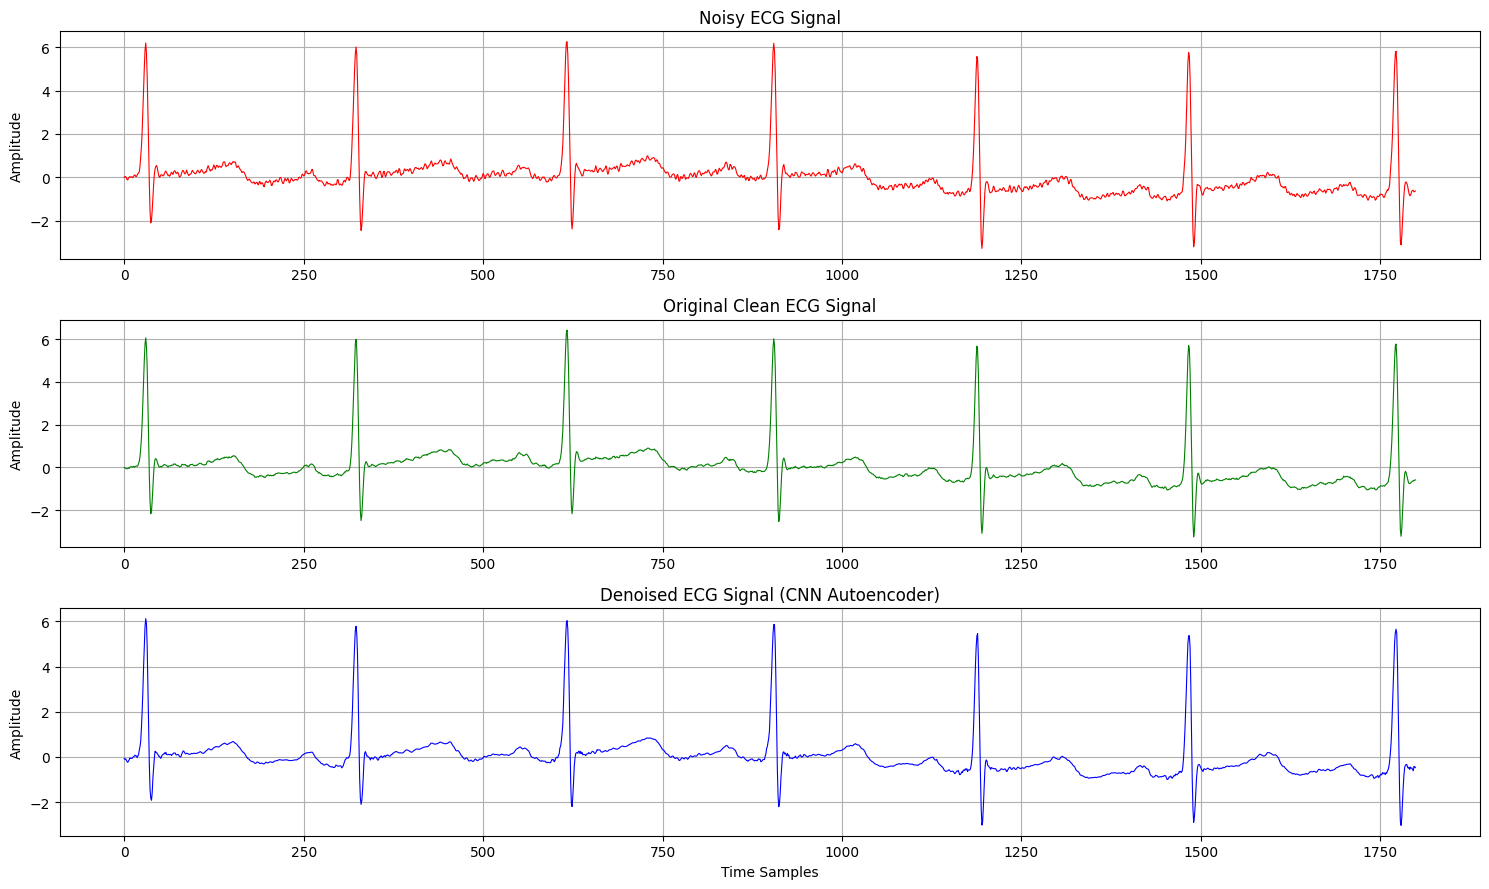

In [57]:

import matplotlib.pyplot as plt
import numpy as np

# Select a test sample
sample_index = 0

# Extract signals
noisy = test_noisy[sample_index].squeeze()
clean = test_clean[sample_index].squeeze()
denoised = denoised_signals[sample_index].squeeze()

# Plot comparison
plt.figure(figsize=(15, 9))

plt.subplot(3, 1, 1)
plt.plot(noisy, color='red', linewidth=0.8)
plt.title("Noisy ECG Signal")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(clean, color='green', linewidth=0.8)
plt.title("Original Clean ECG Signal")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(denoised, color='blue', linewidth=0.8)
plt.title("Denoised ECG Signal (CNN Autoencoder)")
plt.xlabel("Time Samples")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()


In [58]:

import numpy as np
from sklearn.metrics import mean_squared_error

# Flatten ECG signals for metric calculation
clean_flat = test_clean.squeeze()
noisy_flat = test_noisy.squeeze()
denoised_flat = denoised_signals.squeeze()

# Calculate MSE
mse_noisy = mean_squared_error(
    clean_flat.flatten(),
    noisy_flat.flatten()
)

mse_denoised = mean_squared_error(
    clean_flat.flatten(),
    denoised_flat.flatten()
)

# Calculate RMSE
rmse_noisy = np.sqrt(mse_noisy)
rmse_denoised = np.sqrt(mse_denoised)

# Calculate SNR
def calculate_snr(reference, signal):
    noise = reference - signal

    signal_power = np.mean(reference ** 2)
    noise_power = np.mean(noise ** 2)

    return 10 * np.log10(
        signal_power / (noise_power + 1e-12)
    )

snr_before = calculate_snr(clean_flat, noisy_flat)
snr_after = calculate_snr(clean_flat, denoised_flat)

# SNR improvement
snr_improvement = snr_after - snr_before

# Display results
print("ECG DENOISING PERFORMANCE")
print("--------------------------------")
print(f"MSE Before Denoising  : {mse_noisy:.6f}")
print(f"MSE After Denoising   : {mse_denoised:.6f}")
print("--------------------------------")
print(f"RMSE Before Denoising : {rmse_noisy:.6f}")
print(f"RMSE After Denoising  : {rmse_denoised:.6f}")
print("--------------------------------")
print(f"SNR Before Denoising  : {snr_before:.4f} dB")
print(f"SNR After Denoising   : {snr_after:.4f} dB")
print(f"SNR Improvement       : {snr_improvement:.4f} dB")


ECG DENOISING PERFORMANCE
--------------------------------
MSE Before Denoising  : 0.014995
MSE After Denoising   : 0.015271
--------------------------------
RMSE Before Denoising : 0.122455
RMSE After Denoising  : 0.123574
--------------------------------
SNR Before Denoising  : 18.2405 dB
SNR After Denoising   : 18.1614 dB
SNR Improvement       : -0.0791 dB


In [59]:

import numpy as np

print("SIGNAL STATISTICS")
print("-" * 45)

signals_to_check = {
    "Clean ECG": test_clean,
    "Noisy ECG": test_noisy,
    "Denoised ECG": denoised_signals
}

for name, data in signals_to_check.items():
    print(f"\n{name}")
    print("Mean:", np.mean(data))
    print("Standard Deviation:", np.std(data))
    print("Minimum:", np.min(data))
    print("Maximum:", np.max(data))
    print("Shape:", data.shape)


SIGNAL STATISTICS
---------------------------------------------

Clean ECG
Mean: -3.447356e-09
Standard Deviation: 1.0
Minimum: -4.0969906
Maximum: 8.7302265
Shape: (300, 1800, 1)

Noisy ECG
Mean: 0.019096335
Standard Deviation: 1.0084248
Minimum: -4.047383
Maximum: 8.760582
Shape: (300, 1800, 1)

Denoised ECG
Mean: 0.002447293
Standard Deviation: 0.9987941
Minimum: -3.958097
Maximum: 8.773131
Shape: (300, 1800, 1)


RECONSTRUCTION ERROR ANALYSIS
--------------------------------
Average Noisy ECG Error: 0.103858404
Average Denoised ECG Error: 0.098187715
Samples improved: 221
Samples worsened: 79


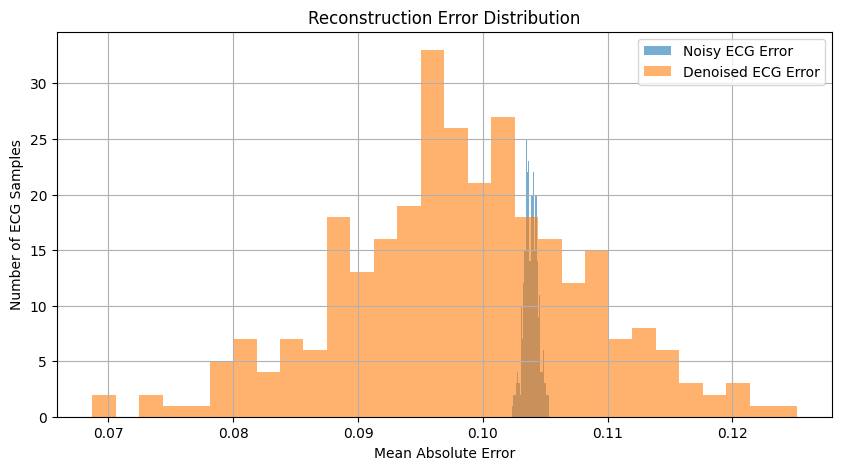

In [60]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate absolute reconstruction errors
noisy_error = np.abs(test_clean - test_noisy)
denoised_error = np.abs(test_clean - denoised_signals)

# Calculate average error for each sample
noisy_sample_errors = np.mean(noisy_error, axis=(1, 2))
denoised_sample_errors = np.mean(denoised_error, axis=(1, 2))

print("RECONSTRUCTION ERROR ANALYSIS")
print("--------------------------------")

print("Average Noisy ECG Error:",
      np.mean(noisy_sample_errors))

print("Average Denoised ECG Error:",
      np.mean(denoised_sample_errors))

print("Samples improved:",
      np.sum(denoised_sample_errors < noisy_sample_errors))

print("Samples worsened:",
      np.sum(denoised_sample_errors > noisy_sample_errors))

# Plot error comparison
plt.figure(figsize=(10, 5))

plt.hist(noisy_sample_errors, bins=30,
         alpha=0.6, label="Noisy ECG Error")

plt.hist(denoised_sample_errors, bins=30,
         alpha=0.6, label="Denoised ECG Error")

plt.title("Reconstruction Error Distribution")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Number of ECG Samples")
plt.legend()
plt.grid(True)
plt.show()


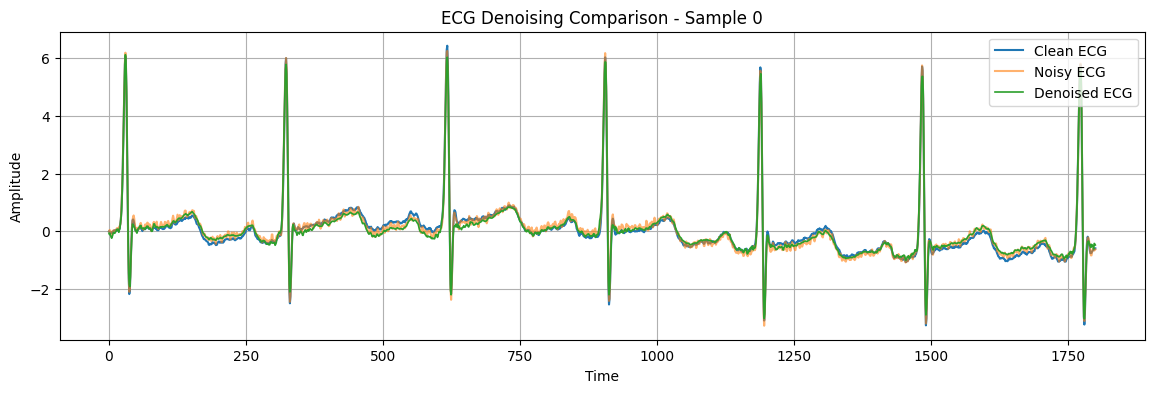

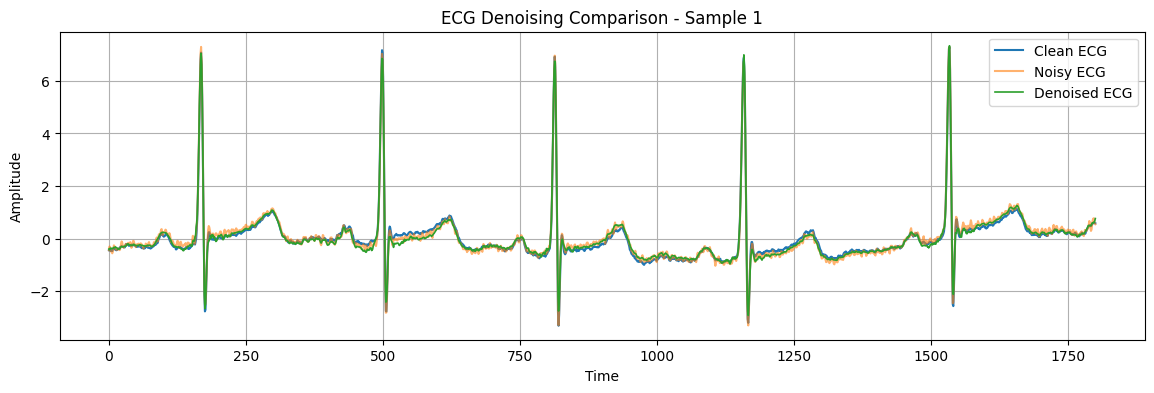

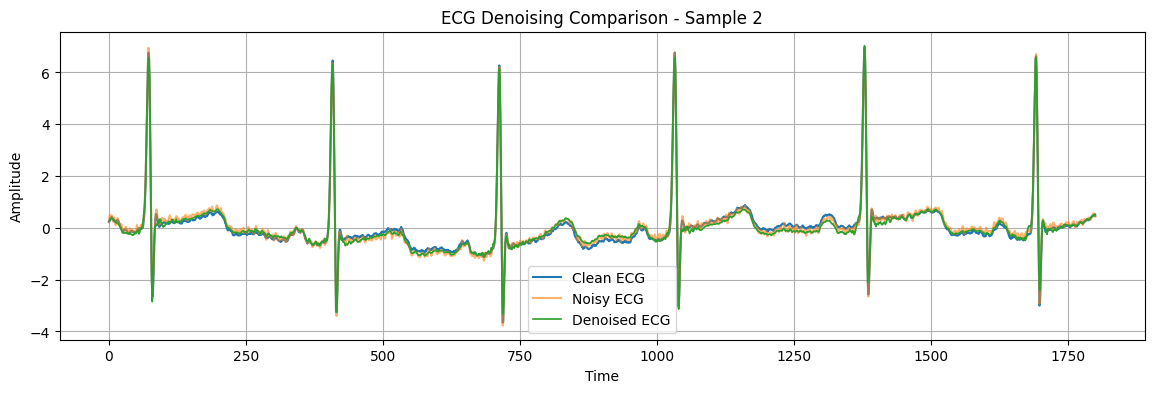

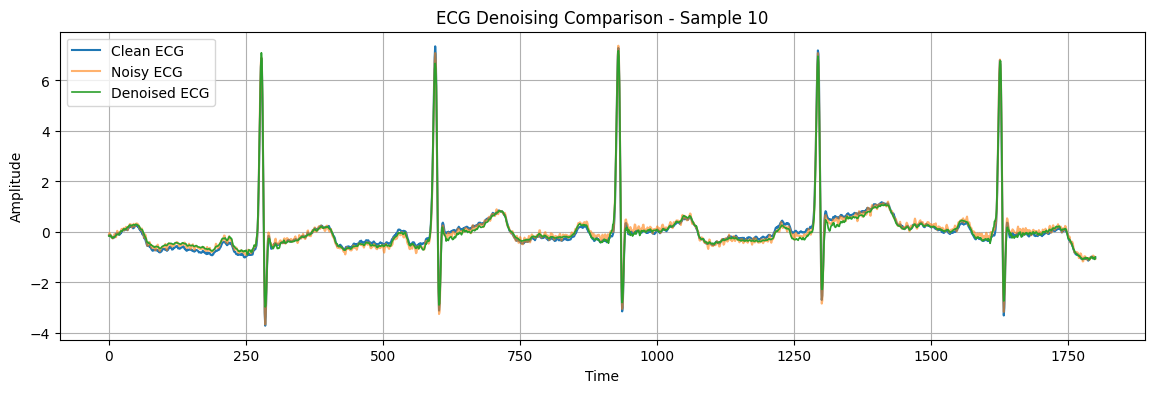

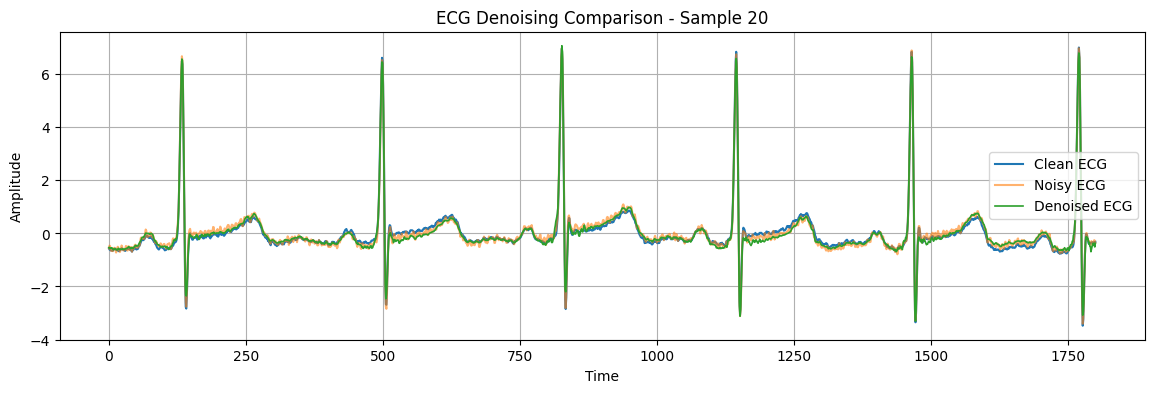

In [61]:
import matplotlib.pyplot as plt
import numpy as np

samples = [0, 1, 2, 10, 20]

for i in samples:
    plt.figure(figsize=(14, 4))

    plt.plot(test_clean[i].squeeze(),
             label="Clean ECG", linewidth=1.5)

    plt.plot(test_noisy[i].squeeze(),
             label="Noisy ECG", alpha=0.6)

    plt.plot(denoised_signals[i].squeeze(),
             label="Denoised ECG", linewidth=1.2)

    plt.title(f"ECG Denoising Comparison - Sample {i}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.show()

DETAILED TEST PERFORMANCE
-----------------------------------
Total test samples: 300

MSE Analysis
Improved samples: 147
Worsened samples: 153

MAE Analysis
Improved samples: 221
Worsened samples: 79

Average MSE Before: 0.014995123
Average MSE After: 0.015270602

Average MAE Before: 0.103858404
Average MAE After: 0.098187715


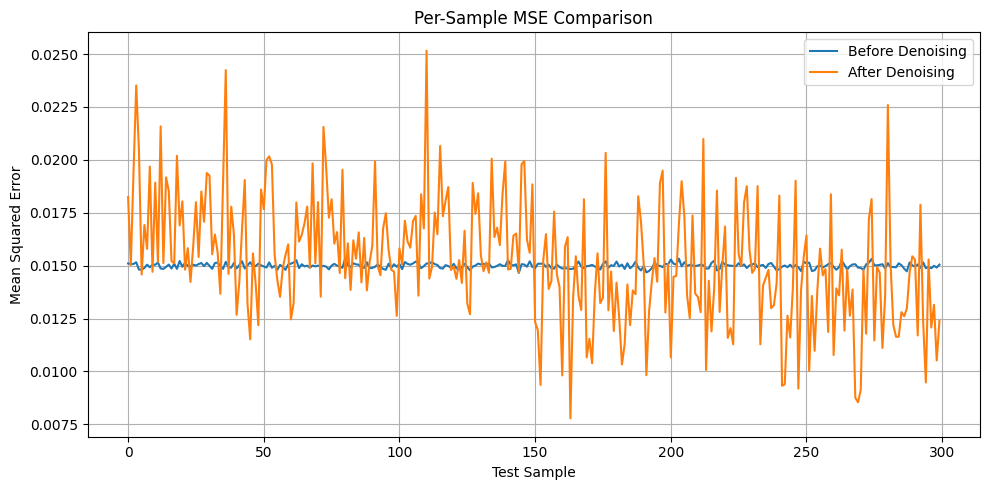

In [62]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate errors for each test sample
mse_before = np.mean(
    (test_clean - test_noisy) ** 2,
    axis=(1, 2)
)

mse_after = np.mean(
    (test_clean - denoised_signals) ** 2,
    axis=(1, 2)
)

mae_before = np.mean(
    np.abs(test_clean - test_noisy),
    axis=(1, 2)
)

mae_after = np.mean(
    np.abs(test_clean - denoised_signals),
    axis=(1, 2)
)

# Calculate improvement percentages
mse_improved = np.sum(mse_after < mse_before)
mae_improved = np.sum(mae_after < mae_before)

print("DETAILED TEST PERFORMANCE")
print("-----------------------------------")
print("Total test samples:", len(test_clean))

print("\nMSE Analysis")
print("Improved samples:", mse_improved)
print("Worsened samples:", 300 - mse_improved)

print("\nMAE Analysis")
print("Improved samples:", mae_improved)
print("Worsened samples:", 300 - mae_improved)

print("\nAverage MSE Before:", np.mean(mse_before))
print("Average MSE After:", np.mean(mse_after))

print("\nAverage MAE Before:", np.mean(mae_before))
print("Average MAE After:", np.mean(mae_after))

# Plot comparison
plt.figure(figsize=(10, 5))

plt.plot(mse_before, label="Before Denoising")
plt.plot(mse_after, label="After Denoising")

plt.title("Per-Sample MSE Comparison")
plt.xlabel("Test Sample")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


INDIVIDUAL SNR EVALUATION
--------------------------------
Average SNR Before: 18.240635
Average SNR After: 18.241606
Average SNR Improvement: 0.00097222644
Samples with improved SNR: 147
Samples with worsened SNR: 153


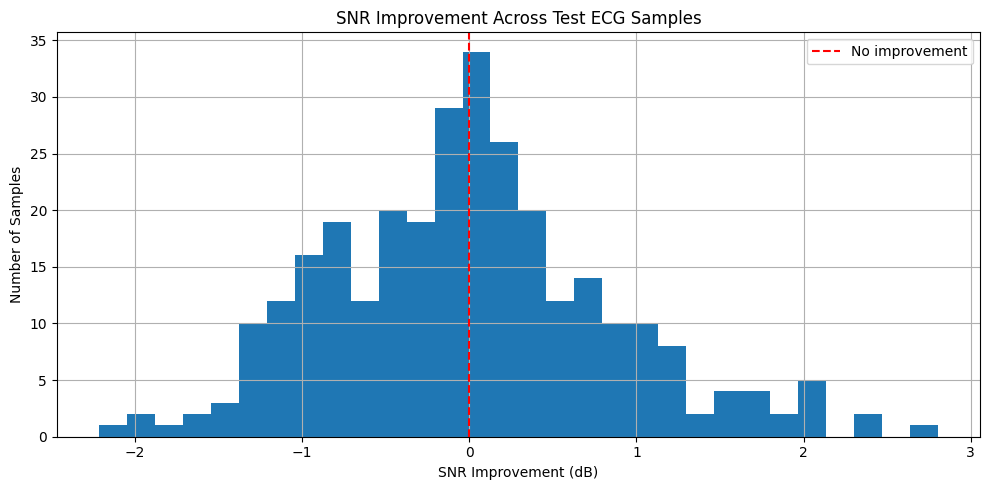

In [63]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate SNR for each ECG sample
def calculate_sample_snr(clean, predicted):
    noise = clean - predicted

    signal_power = np.mean(clean ** 2, axis=(1, 2))
    noise_power = np.mean(noise ** 2, axis=(1, 2))

    return 10 * np.log10(
        (signal_power + 1e-12) /
        (noise_power + 1e-12)
    )

# SNR before and after denoising
snr_before_samples = calculate_sample_snr(
    test_clean, test_noisy
)

snr_after_samples = calculate_sample_snr(
    test_clean, denoised_signals
)

# Calculate improvement
snr_improvements = (
    snr_after_samples - snr_before_samples
)

improved = np.sum(snr_improvements > 0)
worsened = np.sum(snr_improvements < 0)

print("INDIVIDUAL SNR EVALUATION")
print("--------------------------------")

print("Average SNR Before:",
      np.mean(snr_before_samples))

print("Average SNR After:",
      np.mean(snr_after_samples))

print("Average SNR Improvement:",
      np.mean(snr_improvements))

print("Samples with improved SNR:", improved)
print("Samples with worsened SNR:", worsened)

# Plot SNR improvement
plt.figure(figsize=(10, 5))

plt.hist(snr_improvements, bins=30)
plt.axvline(0, linestyle='--', color='red',
            label='No improvement')

plt.title("SNR Improvement Across Test ECG Samples")
plt.xlabel("SNR Improvement (dB)")
plt.ylabel("Number of Samples")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [64]:

import numpy as np
import pandas as pd

# Create performance comparison
results = pd.DataFrame({
    'Sample': np.arange(len(test_clean)),
    'SNR Before': snr_before_samples,
    'SNR After': snr_after_samples,
    'SNR Improvement': snr_improvements,
    'MSE Before': mse_before,
    'MSE After': mse_after,
    'MAE Before': mae_before,
    'MAE After': mae_after
})

# Sort by SNR improvement
results = results.sort_values(
    by='SNR Improvement',
    ascending=False
)

print("TOP 10 IMPROVED ECG SAMPLES")
display(results.head(10))

print("\nTOP 10 WORST ECG SAMPLES")
display(results.tail(10))

# Summary
print("\nOVERALL PERFORMANCE")
print("Mean SNR improvement:",
      np.mean(snr_improvements))

print("Median SNR improvement:",
      np.median(snr_improvements))

print("Best SNR improvement:",
      np.max(snr_improvements))

print("Worst SNR improvement:",
      np.min(snr_improvements))


TOP 10 IMPROVED ECG SAMPLES


,Sample,SNR Before,SNR After,SNR Improvement,MSE Before,MSE After,MAE Before,MAE After
163,163,18.285549,21.089594,2.804045,0.014840,0.007781,0.103133,0.069493
269,269,18.265945,20.684965,2.419020,0.014908,0.008541,0.103559,0.074393
268,268,18.219938,20.581110,2.361172,0.015066,0.008748,0.103381,0.068693
270,270,18.270290,20.396626,2.126335,0.014893,0.009127,0.103677,0.073342
247,247,18.260921,20.368383,2.107462,0.014925,0.009187,0.103627,0.081632
152,152,18.212418,20.287945,2.075527,0.015092,0.009358,0.103477,0.078214
241,241,18.253504,20.305365,2.051861,0.014950,0.009321,0.103706,0.078389
242,242,18.237402,20.273581,2.036179,0.015006,0.009389,0.103966,0.079762
294,294,18.274477,20.233212,1.958735,0.014878,0.009477,0.103520,0.072961
160,160,18.278744,20.083824,1.805080,0.014864,0.009809,0.102357,0.080131



TOP 10 WORST ECG SAMPLES


,Sample,SNR Before,SNR After,SNR Improvement,MSE Before,MSE After,MAE Before,MAE After
18,18,18.283388,16.948063,-1.335325,0.014848,0.020193,0.102596,0.104037
4,4,18.293785,16.893379,-1.400406,0.014812,0.020449,0.103166,0.115915
115,115,18.273499,16.848299,-1.425200,0.014882,0.020662,0.102815,0.102445
212,212,18.235085,16.780514,-1.454571,0.015014,0.020987,0.104286,0.115041
72,72,18.241352,16.663952,-1.577400,0.014992,0.021558,0.103268,0.125156
12,12,18.278278,16.658768,-1.619511,0.014865,0.021584,0.103269,0.120601
280,280,18.204948,16.460239,-1.744709,0.015118,0.022593,0.103724,0.121989
3,3,18.193352,16.286154,-1.907198,0.015159,0.023517,0.104495,0.111190
36,36,18.187496,16.154430,-2.033066,0.015179,0.024241,0.104556,0.108450
110,110,18.209118,15.992929,-2.216189,0.015104,0.025160,0.103958,0.113807



OVERALL PERFORMANCE
Mean SNR improvement: 0.00097222644
Median SNR improvement: -0.0045719147
Best SNR improvement: 2.8040447
Worst SNR improvement: -2.2161894


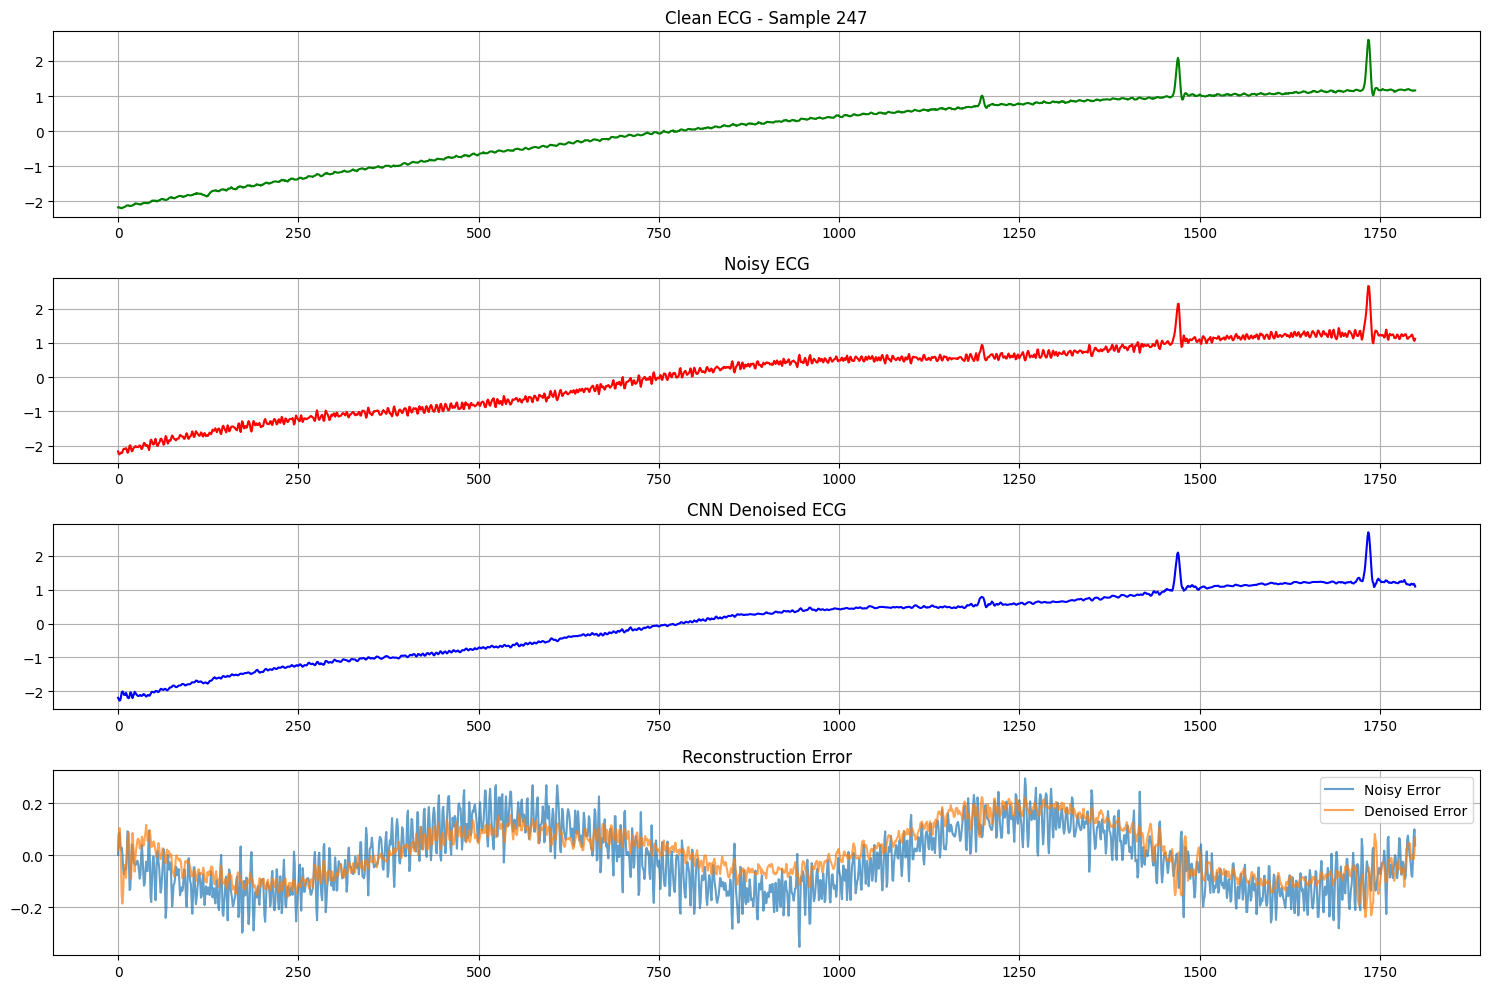


Sample 247
SNR improvement: 2.107462 dB


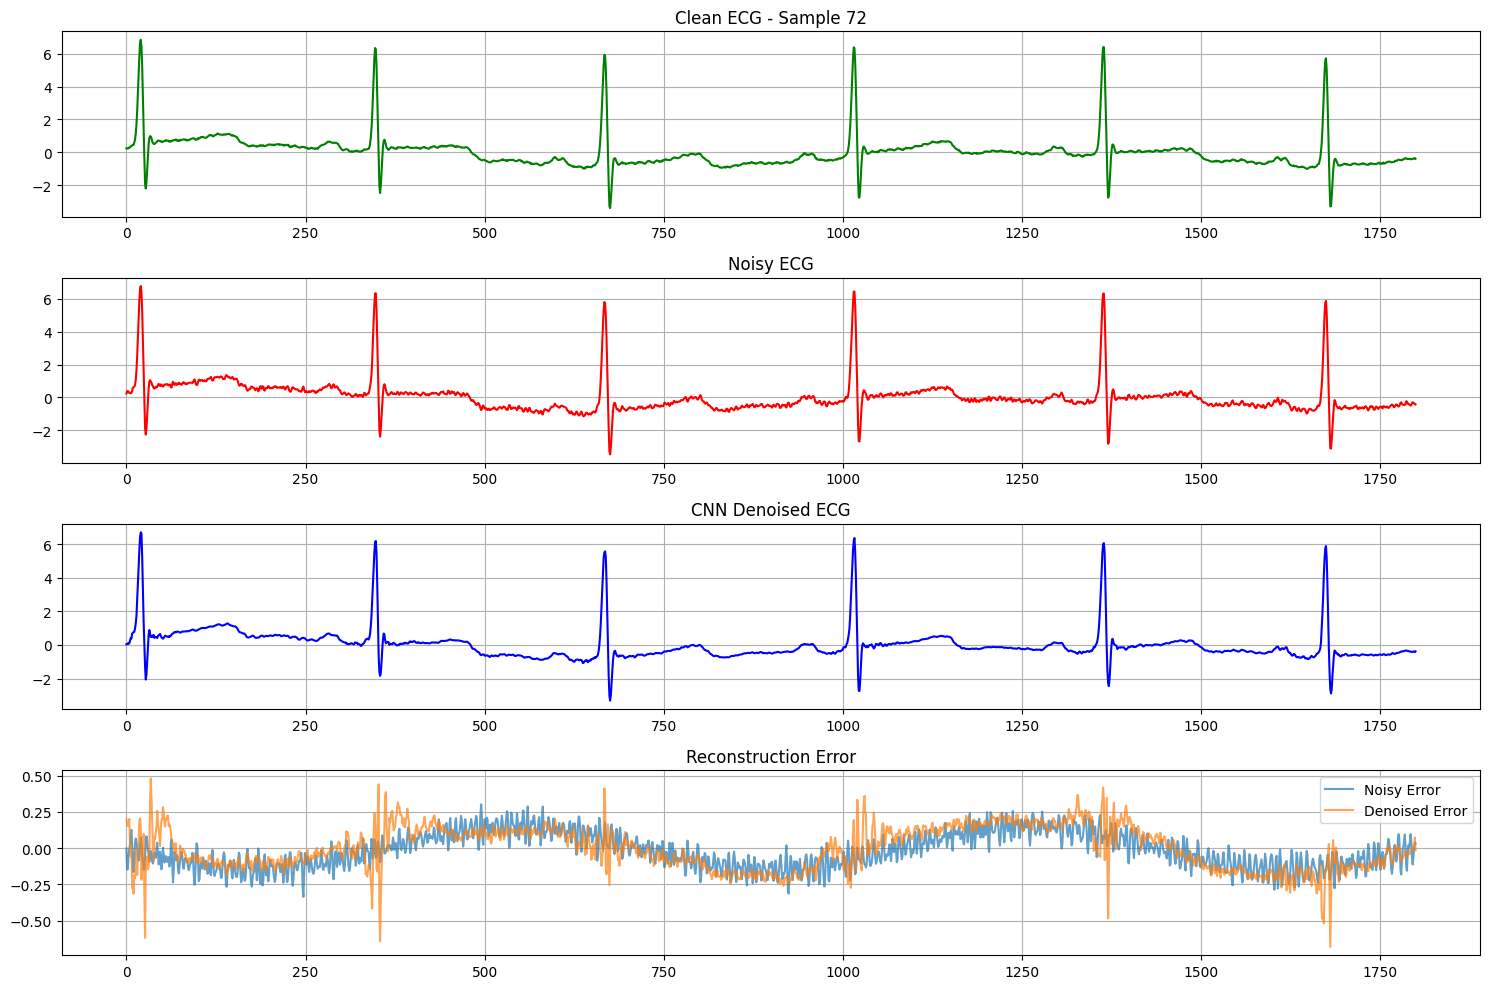


Sample 72
SNR improvement: -1.5774002 dB


In [65]:

import matplotlib.pyplot as plt
import numpy as np

# Best and worst performing samples
sample_indices = [247, 72]

for idx in sample_indices:

    clean = test_clean[idx].squeeze()
    noisy = test_noisy[idx].squeeze()
    denoised = denoised_signals[idx].squeeze()

    # Calculate reconstruction errors
    noisy_error = clean - noisy
    denoised_error = clean - denoised

    plt.figure(figsize=(15, 10))

    # Original clean signal
    plt.subplot(4, 1, 1)
    plt.plot(clean, color='green')
    plt.title(f"Clean ECG - Sample {idx}")
    plt.grid(True)

    # Noisy signal
    plt.subplot(4, 1, 2)
    plt.plot(noisy, color='red')
    plt.title("Noisy ECG")
    plt.grid(True)

    # Denoised signal
    plt.subplot(4, 1, 3)
    plt.plot(denoised, color='blue')
    plt.title("CNN Denoised ECG")
    plt.grid(True)

    # Reconstruction error comparison
    plt.subplot(4, 1, 4)
    plt.plot(noisy_error, label="Noisy Error",
             alpha=0.7)
    plt.plot(denoised_error, label="Denoised Error",
             alpha=0.7)
    plt.title("Reconstruction Error")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    print(f"\nSample {idx}")
    print("SNR improvement:",
          snr_improvements[idx], "dB")


NOISE DISTRIBUTION ANALYSIS
--------------------------------
Average noise standard deviation: 0.12095538
Minimum noise standard deviation: 0.119562864
Maximum noise standard deviation: 0.12245522
Standard deviation across samples: 0.00048788686


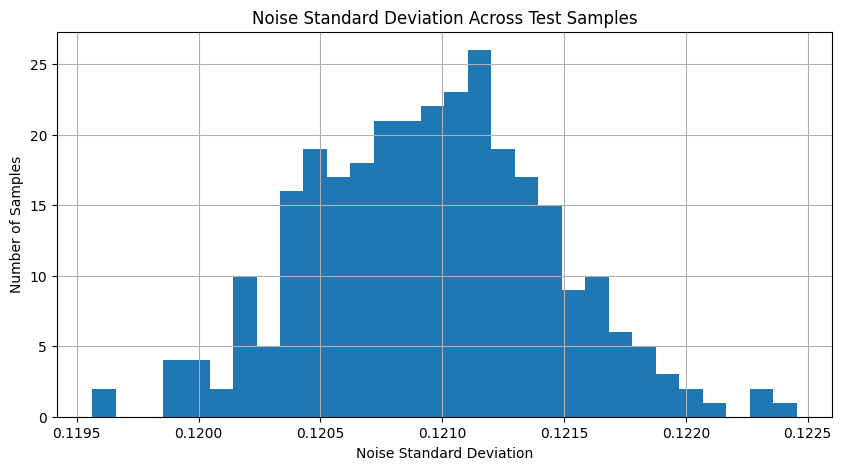

In [66]:

# Calculate noise statistics for every test sample

noise = test_noisy - test_clean

noise_std = np.std(noise, axis=(1, 2))
noise_mean = np.mean(noise, axis=(1, 2))

print("NOISE DISTRIBUTION ANALYSIS")
print("--------------------------------")

print("Average noise standard deviation:",
      np.mean(noise_std))

print("Minimum noise standard deviation:",
      np.min(noise_std))

print("Maximum noise standard deviation:",
      np.max(noise_std))

print("Standard deviation across samples:",
      np.std(noise_std))

plt.figure(figsize=(10, 5))

plt.hist(noise_std, bins=30)
plt.title("Noise Standard Deviation Across Test Samples")
plt.xlabel("Noise Standard Deviation")
plt.ylabel("Number of Samples")
plt.grid(True)
plt.show()


RESIDUAL NOISE ANALYSIS
--------------------------------
Before denoising: 0.12095641
After denoising: 0.12355004
Residual reduction (%): -2.1442673


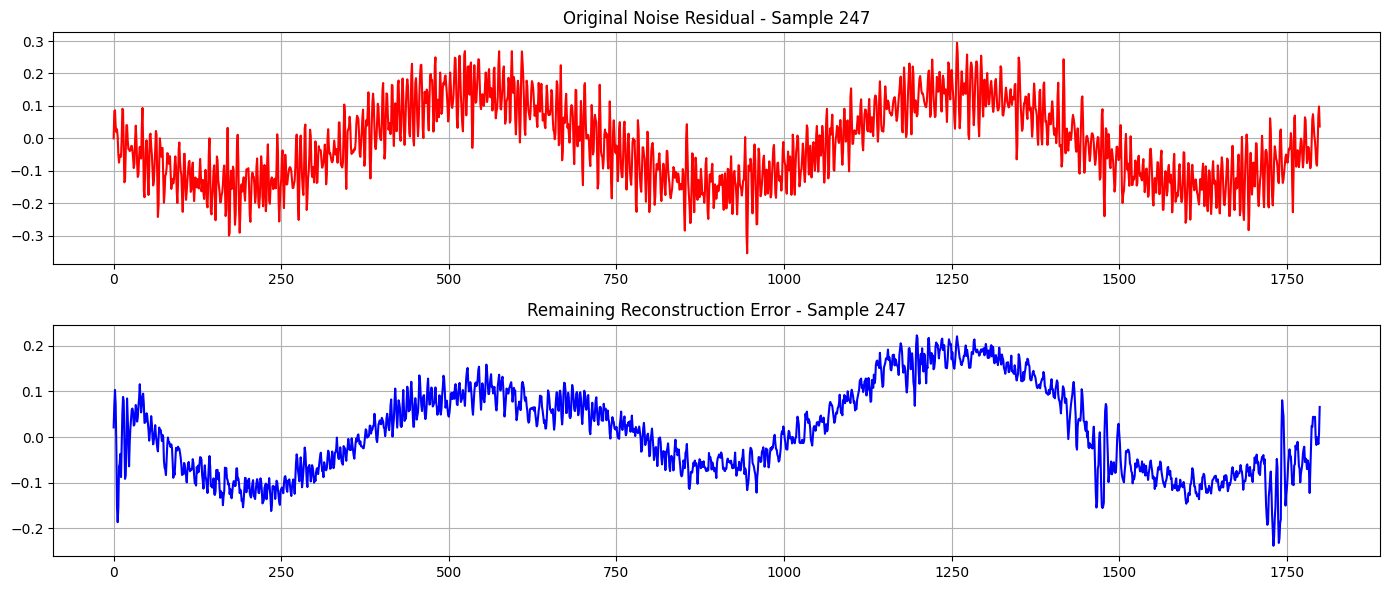

In [67]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate residual errors
noise_before = test_clean - test_noisy
noise_after = test_clean - denoised_signals

# Calculate residual standard deviation
before_std = np.std(noise_before)
after_std = np.std(noise_after)

print("RESIDUAL NOISE ANALYSIS")
print("--------------------------------")
print("Before denoising:", before_std)
print("After denoising:", after_std)

print("Residual reduction (%):",
      ((before_std - after_std) / before_std) * 100)

# Visualize residuals for one sample
sample_index = 247

plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(noise_before[sample_index].squeeze(),
         color='red')
plt.title("Original Noise Residual - Sample 247")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(noise_after[sample_index].squeeze(),
         color='blue')
plt.title("Remaining Reconstruction Error - Sample 247")
plt.grid(True)

plt.tight_layout()
plt.show()


In [111]:
import inspect

print("NOISE GENERATION FUNCTION")
print("-------------------------")
print(inspect.getsource(create_noisy_signal))

print("\nDATA PREPARATION FUNCTION")
print("-------------------------")
print(inspect.getsource(prepare_dataset))

NOISE GENERATION FUNCTION
-------------------------
def create_noisy_signal(clean_signal):

    t = np.arange(len(clean_signal)) / fs

    # Baseline wander
    baseline = 0.15 * np.sin(2 * np.pi * 0.5 * t)

    # 50 Hz power-line noise
    powerline = 0.05 * np.sin(2 * np.pi * 50 * t)

    # Simulated muscle-like noise
    white_noise = rng.normal(0, 1, len(clean_signal))

    emg = sosfiltfilt(emg_sos, white_noise)
    emg = emg / (np.std(emg) + 1e-8) * 0.05

    return clean_signal + baseline + powerline + emg


DATA PREPARATION FUNCTION
-------------------------
def prepare_dataset(record_ids):

    clean_windows = []
    noisy_windows = []

    for record_id in record_ids:

        print("Processing record:", record_id)

        record = wfdb.rdrecord(
            record_id,
            pn_dir='mitdb'
        )

        if record.fs != fs:
            raise ValueError(
                f"Unexpected sampling rate in record {record_id}"
            )

        signal = record.p_signal

In [71]:
import numpy as np

# Calculate errors separately for every ECG window
mse_before = np.mean(
    (test_noisy - test_clean) ** 2,
    axis=(1, 2)
)

mse_after = np.mean(
    (denoised_signals - test_clean) ** 2,
    axis=(1, 2)
)

mae_before = np.mean(
    np.abs(test_noisy - test_clean),
    axis=(1, 2)
)

mae_after = np.mean(
    np.abs(denoised_signals - test_clean),
    axis=(1, 2)
)

print("VERIFIED RESULTS")
print("----------------------------")

print("MSE before:", np.mean(mse_before))
print("MSE after:", np.mean(mse_after))

print("MAE before:", np.mean(mae_before))
print("MAE after:", np.mean(mae_after))

print("MSE improved:", np.sum(mse_after < mse_before))
print("MSE worsened:", np.sum(mse_after > mse_before))

print("MAE improved:", np.sum(mae_after < mae_before))
print("MAE worsened:", np.sum(mae_after > mae_before))

VERIFIED RESULTS
----------------------------
MSE before: 0.014995123
MSE after: 0.015270602
MAE before: 0.103858404
MAE after: 0.098187715
MSE improved: 147
MSE worsened: 153
MAE improved: 221
MAE worsened: 79


In [72]:

import numpy as np
from scipy.signal import butter, sosfiltfilt

fs = 360

# Design a 0.5–40 Hz ECG bandpass filter
sos = butter(
    4,
    [0.5, 40],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply filtering separately to each test signal
filtered_signals = np.zeros_like(test_noisy)

for i in range(len(test_noisy)):
    filtered_signals[i, :, 0] = sosfiltfilt(
        sos,
        test_noisy[i, :, 0]
    )

# Calculate metrics for each approach
def calculate_metrics(reference, estimated):
    mse = np.mean(
        (reference - estimated) ** 2,
        axis=(1, 2)
    )

    mae = np.mean(
        np.abs(reference - estimated),
        axis=(1, 2)
    )

    rmse = np.sqrt(mse)

    signal_power = np.sum(
        reference ** 2,
        axis=(1, 2)
    )

    error_power = np.sum(
        (reference - estimated) ** 2,
        axis=(1, 2)
    )

    snr = 10 * np.log10(
        signal_power / (error_power + 1e-12)
    )

    return np.mean(mse), np.mean(mae), np.mean(rmse), np.mean(snr)


# Compare all three approaches
results = {
    "Noisy ECG": calculate_metrics(test_clean, test_noisy),
    "Traditional Filter": calculate_metrics(test_clean, filtered_signals),
    "CNN Autoencoder": calculate_metrics(test_clean, denoised_signals)
}

print("ECG DENOISING COMPARISON")
print("-" * 75)
print(f"{'Method':<22} {'MSE':<12} {'MAE':<12} {'RMSE':<12} {'SNR (dB)':<12}")

for method, metrics in results.items():
    print(
        f"{method:<22} "
        f"{metrics[0]:<12.6f} "
        f"{metrics[1]:<12.6f} "
        f"{metrics[2]:<12.6f} "
        f"{metrics[3]:<12.4f}"
    )


ECG DENOISING COMPARISON
---------------------------------------------------------------------------
Method                 MSE          MAE          RMSE         SNR (dB)    
Noisy ECG              0.014995     0.103858     0.122454     18.2406     
Traditional Filter     0.166659     0.257062     0.339317     10.9670     
CNN Autoencoder        0.015271     0.098188     0.123013     18.2416     


SIGNAL STATISTICS
--------------------------------------------------

Clean ECG
Min: -4.0969906
Max: 8.7302265
Mean: -3.447356e-09
Std: 1.0
NaN values: 0

Noisy ECG
Min: -4.047383
Max: 8.760582
Mean: 0.019096335
Std: 1.0084248
NaN values: 0

Filtered ECG
Min: -9.212999
Max: 9.966659
Mean: 0.0040541654
Std: 0.9786889
NaN values: 0

CNN ECG
Min: -3.958097
Max: 8.773131
Mean: 0.002447293
Std: 0.9987941
NaN values: 0


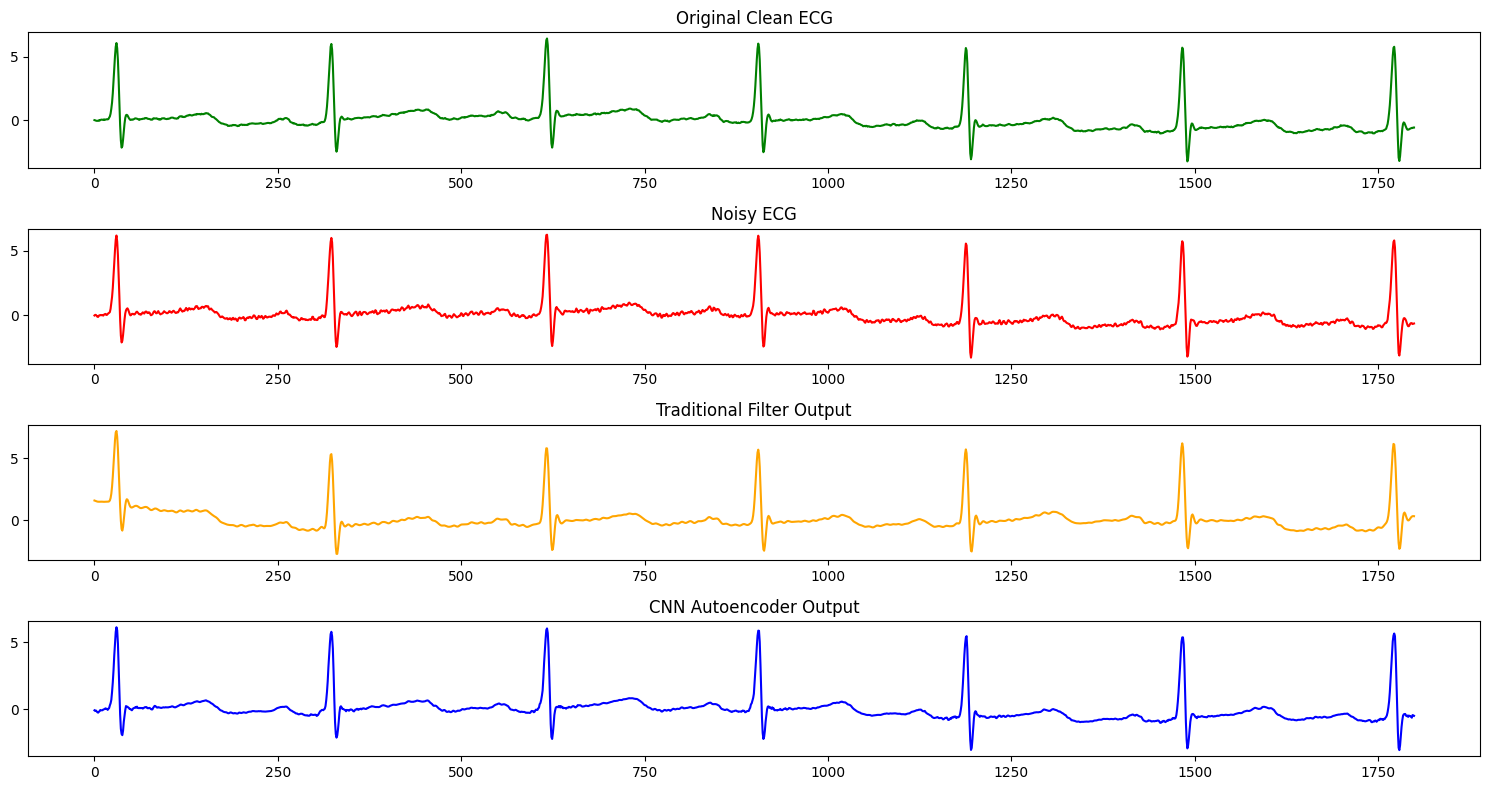

In [73]:

import numpy as np
import matplotlib.pyplot as plt

print("SIGNAL STATISTICS")
print("-" * 50)

for name, signal in [
    ("Clean ECG", test_clean),
    ("Noisy ECG", test_noisy),
    ("Filtered ECG", filtered_signals),
    ("CNN ECG", denoised_signals)
]:
    print(f"\n{name}")
    print("Min:", np.min(signal))
    print("Max:", np.max(signal))
    print("Mean:", np.mean(signal))
    print("Std:", np.std(signal))
    print("NaN values:", np.isnan(signal).sum())

# Inspect one test window
i = 0

plt.figure(figsize=(15, 8))

plt.subplot(4, 1, 1)
plt.plot(test_clean[i, :, 0], color="green")
plt.title("Original Clean ECG")

plt.subplot(4, 1, 2)
plt.plot(test_noisy[i, :, 0], color="red")
plt.title("Noisy ECG")

plt.subplot(4, 1, 3)
plt.plot(filtered_signals[i, :, 0], color="orange")
plt.title("Traditional Filter Output")

plt.subplot(4, 1, 4)
plt.plot(denoised_signals[i, :, 0], color="blue")
plt.title("CNN Autoencoder Output")

plt.tight_layout()
plt.show()


FILTER DIAGNOSTICS
---------------------------------------------
Mean filter MSE: 0.16665947
Median filter MSE: 0.07385518
90th percentile: 0.37139043
Maximum filter MSE: 1.7729062

Windows where filter is worse than noisy:
286 out of 300

Worst filter window: 115
Noisy MSE: 0.014881617
Filtered MSE: 1.7729062
CNN MSE: 0.020661889

Boundary error analysis
Beginning 100 samples: 26.800797
Middle samples: 0.31639966
Ending 100 samples: 0.049119372


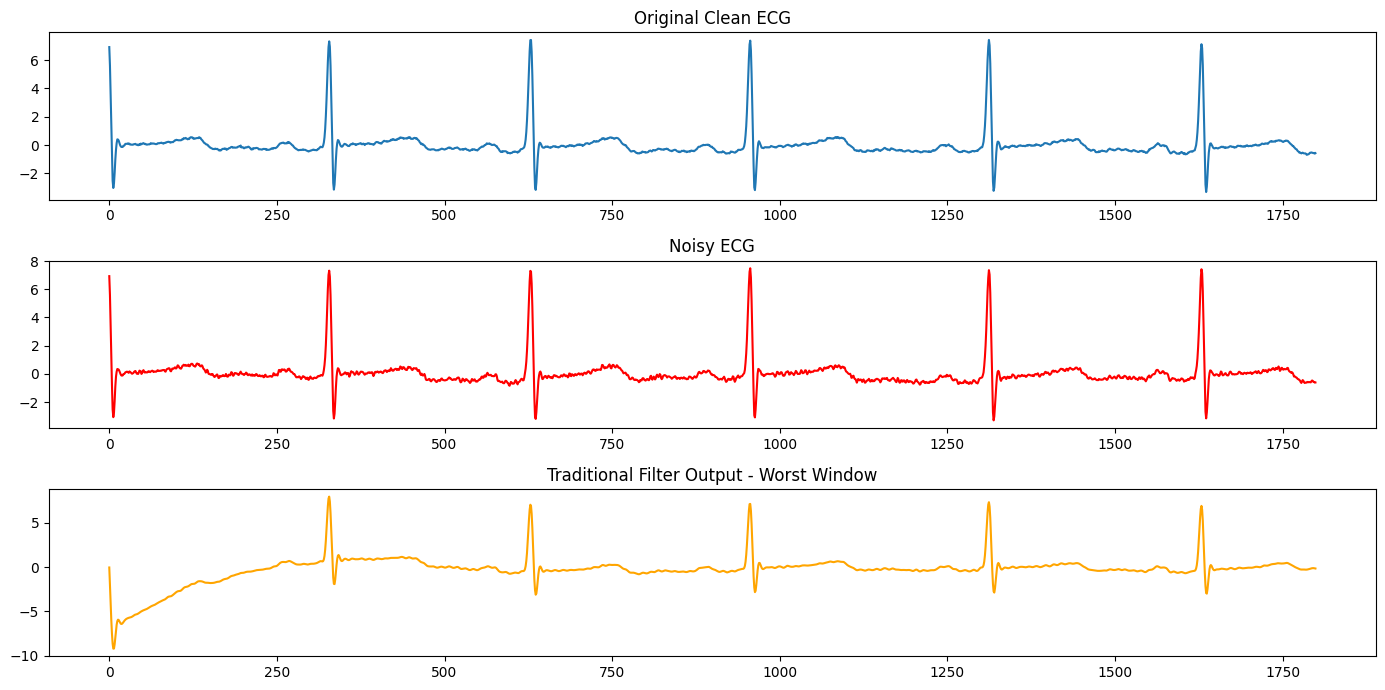

In [74]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate MSE for each test window
filter_mse = np.mean(
    (filtered_signals - test_clean) ** 2,
    axis=(1, 2)
)

cnn_mse = np.mean(
    (denoised_signals - test_clean) ** 2,
    axis=(1, 2)
)

noisy_mse = np.mean(
    (test_noisy - test_clean) ** 2,
    axis=(1, 2)
)

print("FILTER DIAGNOSTICS")
print("-" * 45)

print("Mean filter MSE:", np.mean(filter_mse))
print("Median filter MSE:", np.median(filter_mse))
print("90th percentile:", np.percentile(filter_mse, 90))
print("Maximum filter MSE:", np.max(filter_mse))

print("\nWindows where filter is worse than noisy:")
print(np.sum(filter_mse > noisy_mse), "out of", len(filter_mse))

# Find the worst filter window
worst_idx = np.argmax(filter_mse)

print("\nWorst filter window:", worst_idx)
print("Noisy MSE:", noisy_mse[worst_idx])
print("Filtered MSE:", filter_mse[worst_idx])
print("CNN MSE:", cnn_mse[worst_idx])

# Check error near boundaries versus the middle
clean = test_clean[worst_idx, :, 0]
filtered = filtered_signals[worst_idx, :, 0]

edge_error = np.mean((clean[:100] - filtered[:100])**2)
middle_error = np.mean((clean[100:-100] - filtered[100:-100])**2)
end_error = np.mean((clean[-100:] - filtered[-100:])**2)

print("\nBoundary error analysis")
print("Beginning 100 samples:", edge_error)
print("Middle samples:", middle_error)
print("Ending 100 samples:", end_error)

# Plot the worst window
plt.figure(figsize=(14, 7))

plt.subplot(3, 1, 1)
plt.plot(clean)
plt.title("Original Clean ECG")

plt.subplot(3, 1, 2)
plt.plot(test_noisy[worst_idx, :, 0], color="red")
plt.title("Noisy ECG")

plt.subplot(3, 1, 3)
plt.plot(filtered, color="orange")
plt.title("Traditional Filter Output - Worst Window")

plt.tight_layout()
plt.show()


In [75]:

import numpy as np
from scipy.signal import butter, sosfiltfilt

fs = 360

# ECG bandpass filter
sos = butter(
    4,
    [0.5, 40],
    btype="bandpass",
    fs=fs,
    output="sos"
)

filtered_padded = np.zeros_like(test_noisy)

# Add 1 second of reflected samples on each side
pad_samples = fs

for i in range(len(test_noisy)):

    signal = test_noisy[i, :, 0]

    # Reflection padding
    padded_signal = np.pad(
        signal,
        (pad_samples, pad_samples),
        mode="reflect"
    )

    # Apply filter to padded signal
    filtered_extended = sosfiltfilt(
        sos,
        padded_signal
    )

    # Remove padding
    filtered_padded[i, :, 0] = filtered_extended[
        pad_samples:-pad_samples
    ]

# Evaluate filtered result
def evaluate(signal, reference):
    mse = np.mean((signal - reference)**2, axis=(1, 2))
    mae = np.mean(np.abs(signal - reference), axis=(1, 2))
    rmse = np.sqrt(mse)

    power = np.sum(reference**2, axis=(1, 2))
    error = np.sum((reference - signal)**2, axis=(1, 2))

    snr = 10 * np.log10(power / (error + 1e-12))

    return np.mean(mse), np.mean(mae), np.mean(rmse), np.mean(snr)

print("REFLECTION-PADDED FILTER RESULTS")
print("--------------------------------")

print("Noisy ECG:", evaluate(test_noisy, test_clean))
print("Old Filter:", evaluate(filtered_signals, test_clean))
print("New Filter:", evaluate(filtered_padded, test_clean))
print("CNN:", evaluate(denoised_signals, test_clean))

new_filter_mse = np.mean(
    (filtered_padded - test_clean)**2,
    axis=(1, 2)
)

print(
    "\nNew filter worse than noisy:",
    np.sum(new_filter_mse > noisy_mse),
    "out of",
    len(new_filter_mse)
)


REFLECTION-PADDED FILTER RESULTS
--------------------------------
Noisy ECG: (np.float32(0.014995123), np.float32(0.103858404), np.float32(0.12245362), np.float32(18.240635))
Old Filter: (np.float32(0.16665947), np.float32(0.25706178), np.float32(0.3393166), np.float32(10.966951))
New Filter: (np.float32(0.10592745), np.float32(0.22634506), np.float32(0.27651155), np.float32(12.562858))
CNN: (np.float32(0.015270602), np.float32(0.098187715), np.float32(0.12301261), np.float32(18.241606))

New filter worse than noisy: 270 out of 300


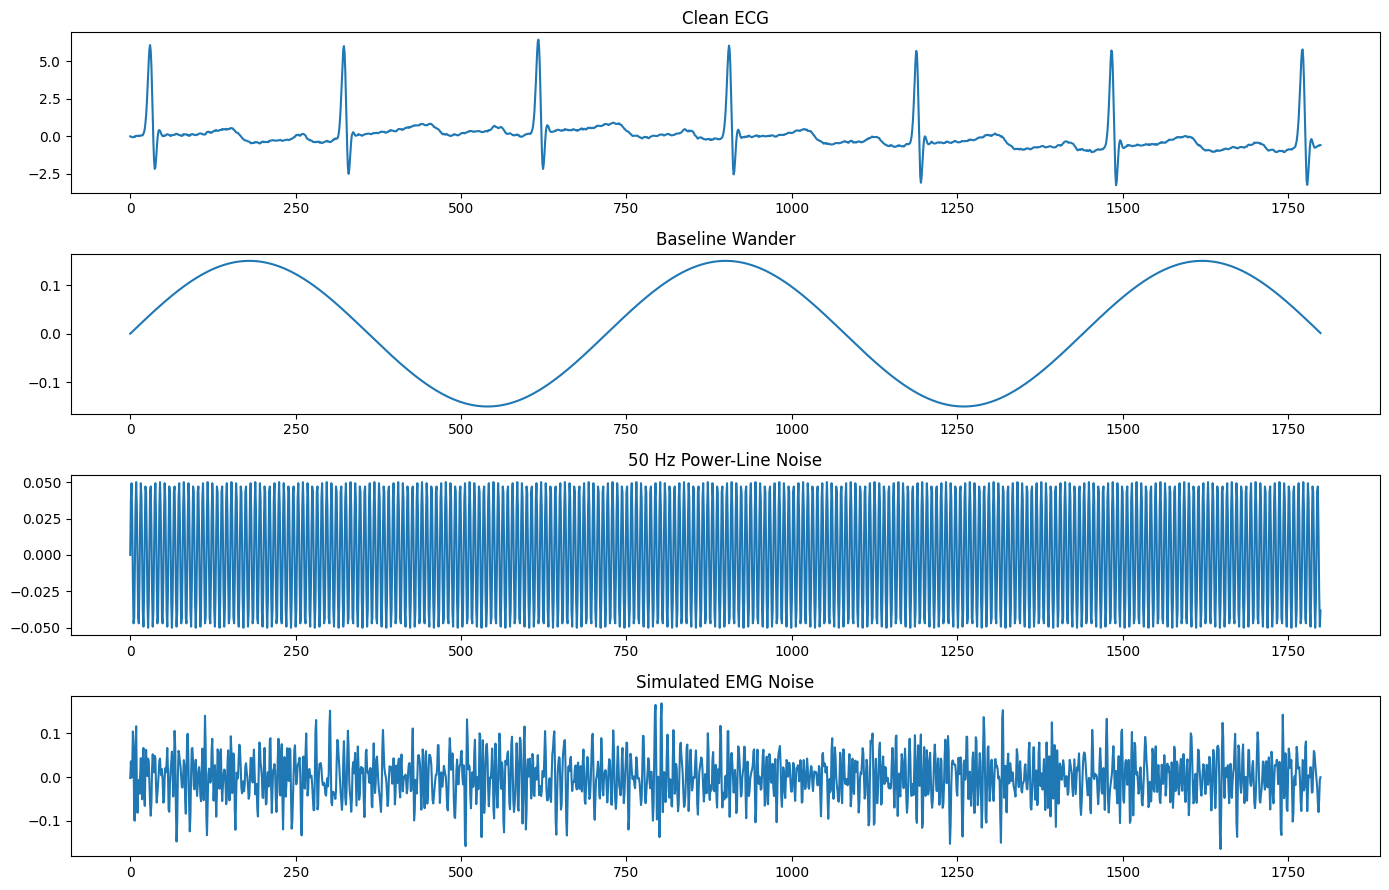

Baseline noise STD: 0.10433239366806649
Powerline noise STD: 0.03535533905932737
EMG noise STD: 0.04999999922398638


In [76]:

# Inspect individual noise components

clean = test_clean[0, :, 0]

t = np.arange(len(clean)) / fs

baseline = 0.15 * np.sin(2 * np.pi * 0.5 * t)
powerline = 0.05 * np.sin(2 * np.pi * 50 * t)

white_noise = rng.normal(0, 1, len(clean))
emg = sosfiltfilt(emg_sos, white_noise)
emg = emg / (np.std(emg) + 1e-8) * 0.05

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 9))

plt.subplot(4, 1, 1)
plt.plot(clean)
plt.title("Clean ECG")

plt.subplot(4, 1, 2)
plt.plot(baseline)
plt.title("Baseline Wander")

plt.subplot(4, 1, 3)
plt.plot(powerline)
plt.title("50 Hz Power-Line Noise")

plt.subplot(4, 1, 4)
plt.plot(emg)
plt.title("Simulated EMG Noise")

plt.tight_layout()
plt.show()

print("Baseline noise STD:", np.std(baseline))
print("Powerline noise STD:", np.std(powerline))
print("EMG noise STD:", np.std(emg))


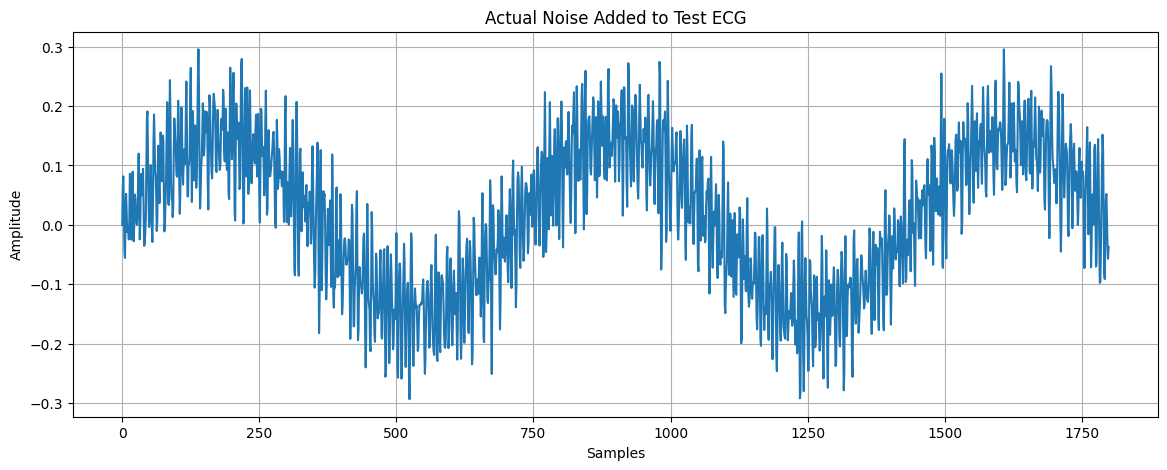

Actual noise STD: 0.121405184
Actual noise mean: 0.019087804
Actual noise maximum: 0.29552266
Actual noise minimum: -0.293221


In [77]:

# Actual noise added to the first test ECG window

actual_noise = test_noisy[0, :, 0] - test_clean[0, :, 0]

plt.figure(figsize=(14, 5))

plt.plot(actual_noise)
plt.title("Actual Noise Added to Test ECG")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

print("Actual noise STD:", np.std(actual_noise))
print("Actual noise mean:", np.mean(actual_noise))
print("Actual noise maximum:", np.max(actual_noise))
print("Actual noise minimum:", np.min(actual_noise))


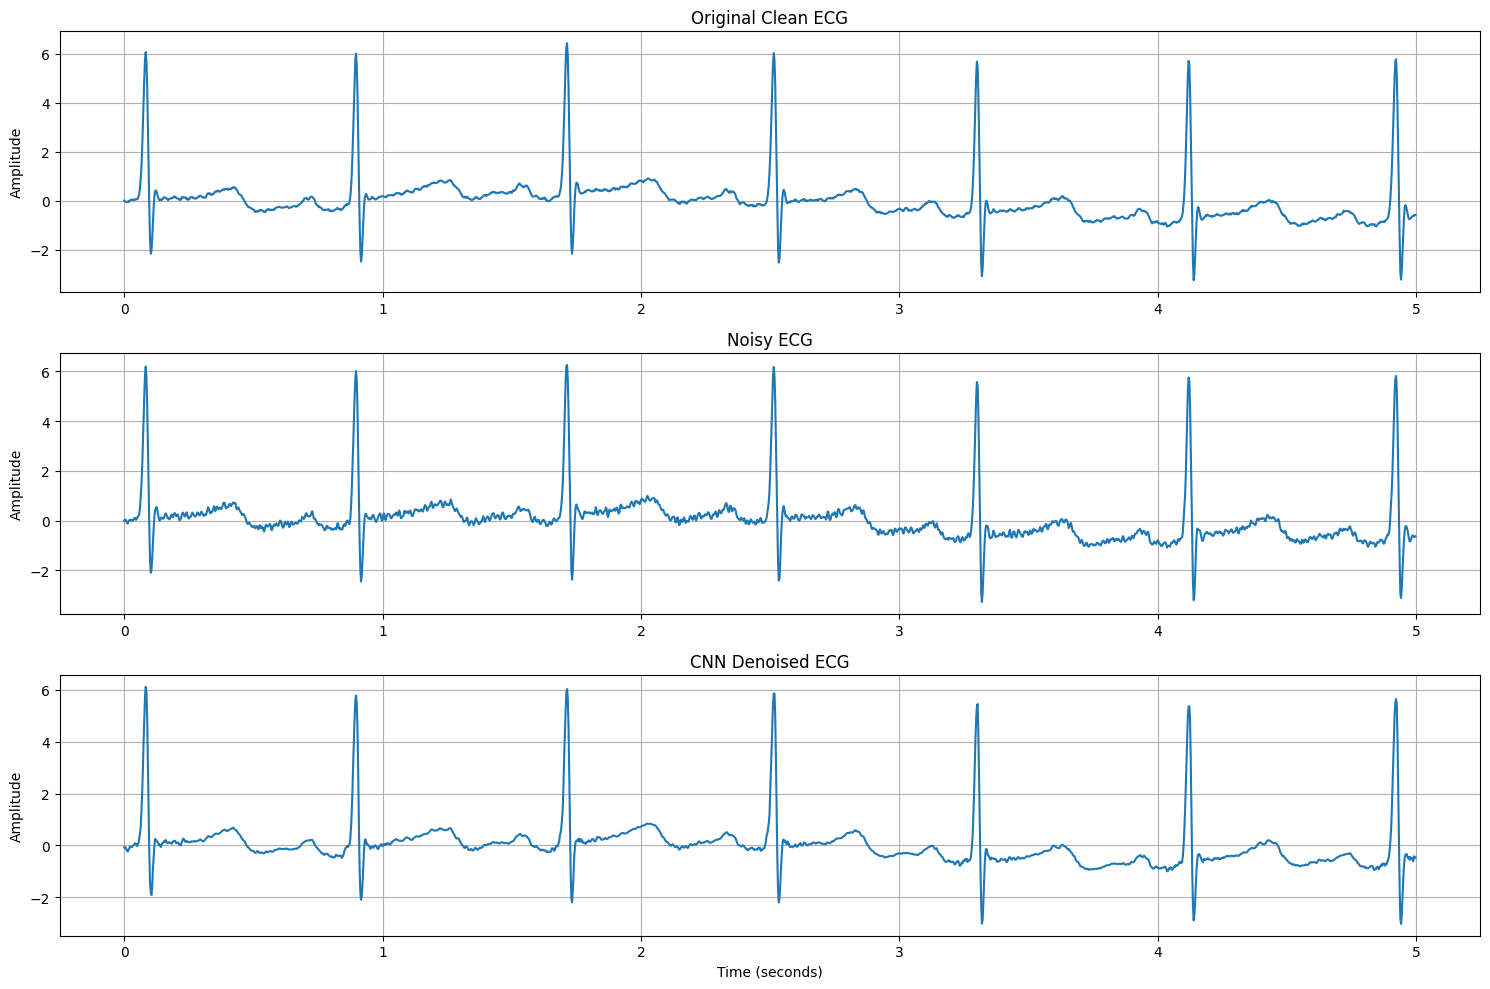

In [78]:

import matplotlib.pyplot as plt
import numpy as np

# Select one test ECG window
i = 0

clean = test_clean[i, :, 0]
noisy = test_noisy[i, :, 0]
denoised = denoised_signals[i, :, 0]

time = np.arange(len(clean)) / fs

plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(time, clean)
plt.title("Original Clean ECG")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(time, noisy)
plt.title("Noisy ECG")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(time, denoised)
plt.title("CNN Denoised ECG")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()


In [79]:

import numpy as np

i = 0

clean = test_clean[i, :, 0]
noisy = test_noisy[i, :, 0]
denoised = denoised_signals[i, :, 0]

print("ECG COMPARISON")
print("-" * 40)

for name, signal in [
    ("Clean ECG", clean),
    ("Noisy ECG", noisy),
    ("CNN Denoised ECG", denoised)
]:
    print(f"\n{name}")
    print("Mean:", np.mean(signal))
    print("STD:", np.std(signal))
    print("Minimum:", np.min(signal))
    print("Maximum:", np.max(signal))

print("\nRECONSTRUCTION ERRORS")
print("-" * 40)

print("Noisy MSE:",
      np.mean((noisy - clean)**2))

print("Denoised MSE:",
      np.mean((denoised - clean)**2))

print("Noisy MAE:",
      np.mean(np.abs(noisy - clean)))

print("Denoised MAE:",
      np.mean(np.abs(denoised - clean)))


ECG COMPARISON
----------------------------------------

Clean ECG
Mean: -3.390842e-08
STD: 1.0
Minimum: -3.2549944
Maximum: 6.4282074

Noisy ECG
Mean: 0.019087762
STD: 0.999437
Minimum: -3.2674947
Maximum: 6.248788

CNN Denoised ECG
Mean: -0.0004745229
STD: 0.97023255
Minimum: -3.0278997
Maximum: 6.1201825

RECONSTRUCTION ERRORS
----------------------------------------
Noisy MSE: 0.015103562
Denoised MSE: 0.018242527
Noisy MAE: 0.10425308
Denoised MAE: 0.11071114


In [80]:

import numpy as np

# Calculate errors for every test window
noisy_mse = np.mean(
    (test_noisy - test_clean)**2,
    axis=(1, 2)
)

denoised_mse = np.mean(
    (denoised_signals - test_clean)**2,
    axis=(1, 2)
)

noisy_mae = np.mean(
    np.abs(test_noisy - test_clean),
    axis=(1, 2)
)

denoised_mae = np.mean(
    np.abs(denoised_signals - test_clean),
    axis=(1, 2)
)

# Count improvements
mse_improved = np.sum(denoised_mse < noisy_mse)
mae_improved = np.sum(denoised_mae < noisy_mae)

print("OVERALL TEST SET EVALUATION")
print("-" * 45)

print("Total test windows:", len(test_clean))

print("\nMSE")
print("Noisy average:", np.mean(noisy_mse))
print("CNN average:", np.mean(denoised_mse))
print("Improved windows:", mse_improved)
print("Worsened windows:", len(test_clean) - mse_improved)

print("\nMAE")
print("Noisy average:", np.mean(noisy_mae))
print("CNN average:", np.mean(denoised_mae))
print("Improved windows:", mae_improved)
print("Worsened windows:", len(test_clean) - mae_improved)

print("\nMEDIAN MSE")
print("Noisy:", np.median(noisy_mse))
print("CNN:", np.median(denoised_mse))

print("\nMEDIAN MAE")
print("Noisy:", np.median(noisy_mae))
print("CNN:", np.median(denoised_mae))


OVERALL TEST SET EVALUATION
---------------------------------------------
Total test windows: 300

MSE
Noisy average: 0.014995123
CNN average: 0.015270602
Improved windows: 147
Worsened windows: 153

MAE
Noisy average: 0.103858404
CNN average: 0.098187715
Improved windows: 221
Worsened windows: 79

MEDIAN MSE
Noisy: 0.014994254
CNN: 0.015040413

MEDIAN MAE
Noisy: 0.10386635
CNN: 0.098119274


FIVE WORST WINDOWS
------------------------------------------------------------
Window 110: Noisy MSE = 0.015104, CNN MSE = 0.025160, Difference = 0.010056
Window 36: Noisy MSE = 0.015179, CNN MSE = 0.024241, Difference = 0.009062
Window 3: Noisy MSE = 0.015159, CNN MSE = 0.023517, Difference = 0.008358
Window 280: Noisy MSE = 0.015118, CNN MSE = 0.022593, Difference = 0.007475
Window 12: Noisy MSE = 0.014865, CNN MSE = 0.021584, Difference = 0.006718


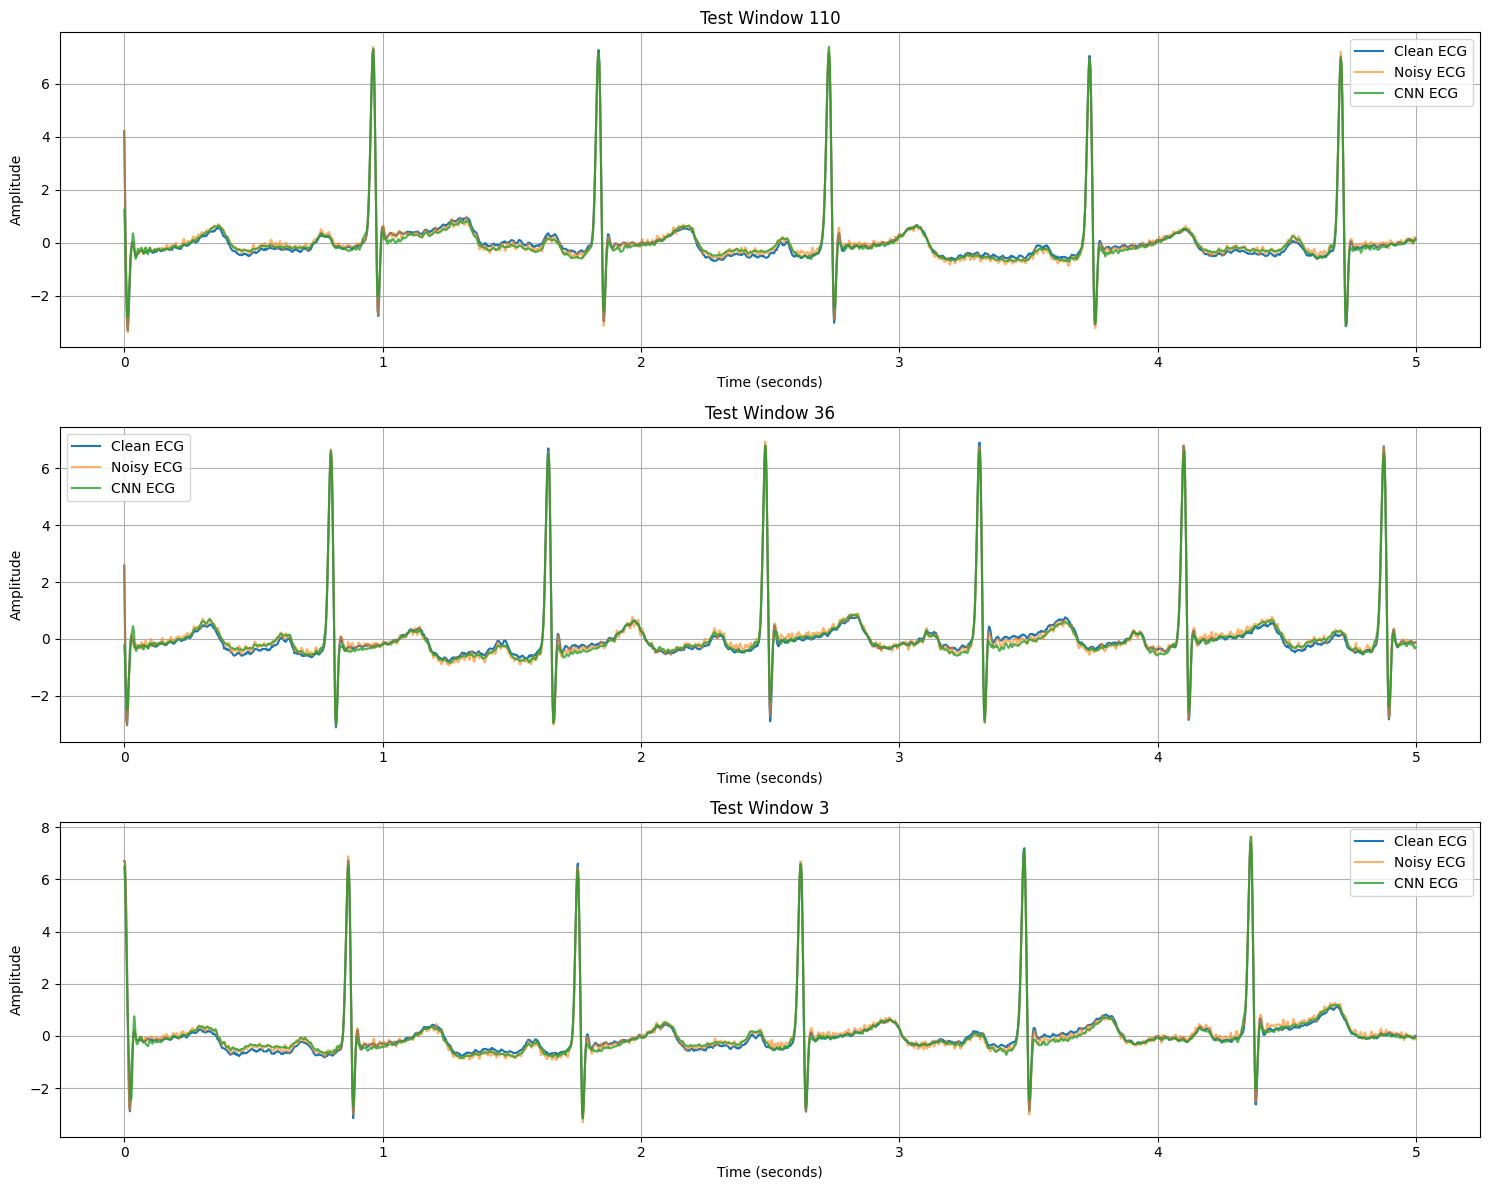

In [81]:

import numpy as np
import matplotlib.pyplot as plt

# Find the 5 windows with the largest MSE deterioration
difference = denoised_mse - noisy_mse

worst_indices = np.argsort(difference)[-5:][::-1]

print("FIVE WORST WINDOWS")
print("-" * 60)

for idx in worst_indices:
    print(
        f"Window {idx}: "
        f"Noisy MSE = {noisy_mse[idx]:.6f}, "
        f"CNN MSE = {denoised_mse[idx]:.6f}, "
        f"Difference = {difference[idx]:.6f}"
    )

# Plot the three signals for the worst 3 windows
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

for ax, idx in zip(axes, worst_indices[:3]):

    clean = test_clean[idx, :, 0]
    noisy = test_noisy[idx, :, 0]
    denoised = denoised_signals[idx, :, 0]

    time = np.arange(len(clean)) / fs

    ax.plot(time, clean, label="Clean ECG")
    ax.plot(time, noisy, label="Noisy ECG", alpha=0.6)
    ax.plot(time, denoised, label="CNN ECG", alpha=0.8)

    ax.set_title(f"Test Window {idx}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()


In [82]:

# Detailed analysis of the five worst windows

print("DETAILED CNN RECONSTRUCTION ANALYSIS")
print("=" * 65)

for idx in worst_indices:

    clean = test_clean[idx, :, 0]
    noisy = test_noisy[idx, :, 0]
    denoised = denoised_signals[idx, :, 0]

    print(f"\nWINDOW: {idx}")
    print("-" * 45)

    print("Clean STD:", np.std(clean))
    print("Noisy STD:", np.std(noisy))
    print("CNN STD:", np.std(denoised))

    print("Clean amplitude range:",
          np.max(clean) - np.min(clean))

    print("Noisy amplitude range:",
          np.max(noisy) - np.min(noisy))

    print("CNN amplitude range:",
          np.max(denoised) - np.min(denoised))

    print("Clean-CNN correlation:",
          np.corrcoef(clean, denoised)[0, 1])

    print("Clean-Noisy correlation:",
          np.corrcoef(clean, noisy)[0, 1])

    print("CNN maximum absolute error:",
          np.max(np.abs(clean - denoised)))


DETAILED CNN RECONSTRUCTION ANALYSIS

WINDOW: 110
---------------------------------------------
Clean STD: 0.99999994
Noisy STD: 1.000266
CNN STD: 0.98322767
Clean amplitude range: 10.630194
Noisy amplitude range: 10.768223
CNN amplitude range: 10.552533
Clean-CNN correlation: 0.9874356741900134
Clean-Noisy correlation: 0.9926314844952913
CNN maximum absolute error: 2.9693995

WINDOW: 36
---------------------------------------------
Clean STD: 0.99999994
Noisy STD: 1.0065459
CNN STD: 0.9897912
Clean amplitude range: 10.016787
Noisy amplitude range: 9.98907
CNN amplitude range: 9.838061
Clean-CNN correlation: 0.9878598094834438
Clean-Noisy correlation: 0.992662821920118
CNN maximum absolute error: 2.8074212

WINDOW: 3
---------------------------------------------
Clean STD: 0.99999994
Noisy STD: 1.0111667
CNN STD: 0.9887751
Clean amplitude range: 10.553455
Noisy amplitude range: 10.937135
CNN amplitude range: 10.785644
Clean-CNN correlation: 0.9882288006525517
Clean-Noisy correlation: 0


Window: 110
Maximum error: 2.9693995
Position: 0
Time in seconds: 0.0


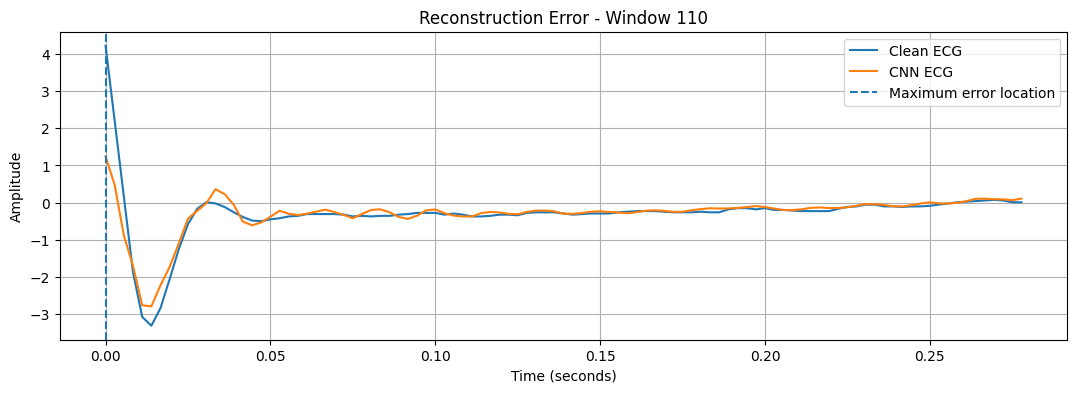


Window: 36
Maximum error: 2.8074212
Position: 0
Time in seconds: 0.0


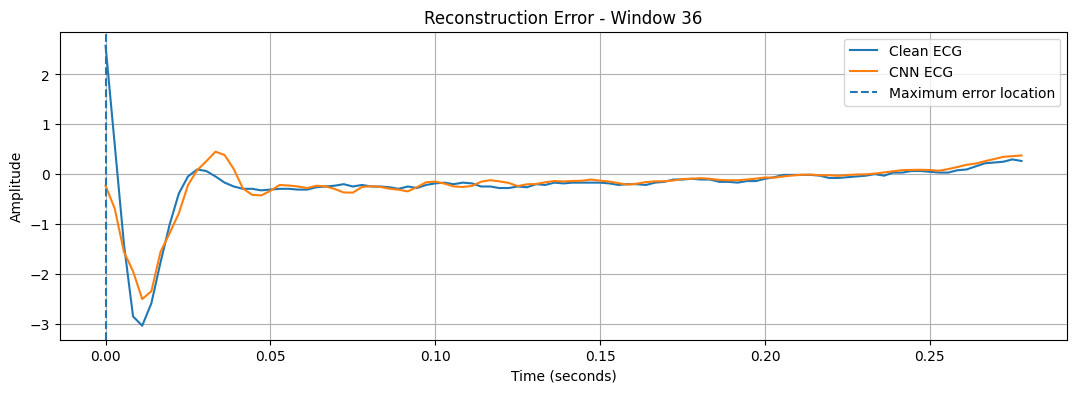


Window: 3
Maximum error: 1.6332599
Position: 7
Time in seconds: 0.019444444444444445


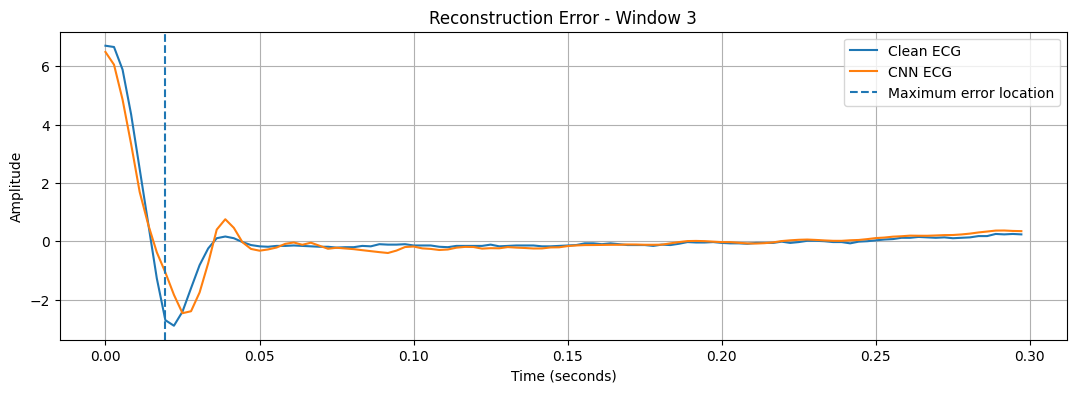

In [83]:

# Find where the CNN makes its largest error

for idx in worst_indices[:3]:

    clean = test_clean[idx, :, 0]
    denoised = denoised_signals[idx, :, 0]

    error = np.abs(clean - denoised)

    max_position = np.argmax(error)

    print("\nWindow:", idx)
    print("Maximum error:", error[max_position])
    print("Position:", max_position)
    print("Time in seconds:", max_position / fs)

    start = max(0, max_position - 100)
    end = min(len(clean), max_position + 101)

    plt.figure(figsize=(13, 4))

    plt.plot(np.arange(start, end) / fs,
             clean[start:end], label="Clean ECG")

    plt.plot(np.arange(start, end) / fs,
             denoised[start:end], label="CNN ECG")

    plt.axvline(max_position / fs,
                linestyle="--",
                label="Maximum error location")

    plt.title(f"Reconstruction Error - Window {idx}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid()
    plt.show()


In [84]:

# Compare reconstruction errors at different positions

absolute_error = np.abs(test_clean - denoised_signals)

beginning_error = np.mean(absolute_error[:, :100, :])
middle_error = np.mean(absolute_error[:, 850:950, :])
ending_error = np.mean(absolute_error[:, -100:, :])

print("BOUNDARY ERROR ANALYSIS")
print("-" * 45)

print("Beginning 100 samples:", beginning_error)
print("Middle 100 samples:", middle_error)
print("Ending 100 samples:", ending_error)

print("\nERROR RATIOS")

print("Beginning / Middle:",
      beginning_error / (middle_error + 1e-8))

print("Ending / Middle:",
      ending_error / (middle_error + 1e-8))


BOUNDARY ERROR ANALYSIS
---------------------------------------------
Beginning 100 samples: 0.07220265
Middle 100 samples: 0.11892399
Ending 100 samples: 0.068117216

ERROR RATIOS
Beginning / Middle: 0.60713273
Ending / Middle: 0.5727794


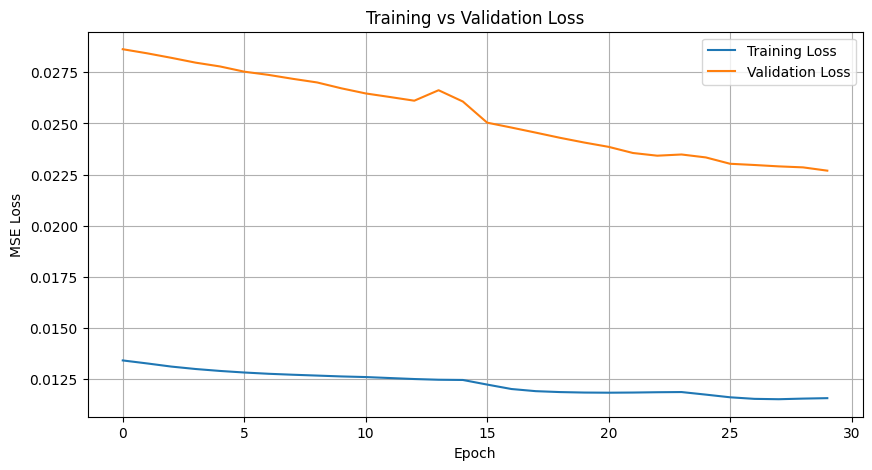

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


In [86]:
for i, (train, val) in enumerate(
    zip(history.history['loss'], history.history['val_loss'])
):
    print(f"Epoch {i+1}: Train={train:.5f}, Val={val:.5f}")

Epoch 1: Train=0.01342, Val=0.02863
Epoch 2: Train=0.01327, Val=0.02843
Epoch 3: Train=0.01312, Val=0.02821
Epoch 4: Train=0.01300, Val=0.02797
Epoch 5: Train=0.01290, Val=0.02779
Epoch 6: Train=0.01283, Val=0.02753
Epoch 7: Train=0.01276, Val=0.02737
Epoch 8: Train=0.01272, Val=0.02718
Epoch 9: Train=0.01268, Val=0.02700
Epoch 10: Train=0.01263, Val=0.02672
Epoch 11: Train=0.01260, Val=0.02647
Epoch 12: Train=0.01256, Val=0.02629
Epoch 13: Train=0.01251, Val=0.02611
Epoch 14: Train=0.01247, Val=0.02662
Epoch 15: Train=0.01246, Val=0.02607
Epoch 16: Train=0.01224, Val=0.02504
Epoch 17: Train=0.01202, Val=0.02480
Epoch 18: Train=0.01191, Val=0.02455
Epoch 19: Train=0.01187, Val=0.02430
Epoch 20: Train=0.01185, Val=0.02407
Epoch 21: Train=0.01184, Val=0.02386
Epoch 22: Train=0.01185, Val=0.02356
Epoch 23: Train=0.01186, Val=0.02342
Epoch 24: Train=0.01187, Val=0.02348
Epoch 25: Train=0.01174, Val=0.02334
Epoch 26: Train=0.01161, Val=0.02303
Epoch 27: Train=0.01154, Val=0.02297
Epoch 28: 

In [87]:
train_loss = history.history['loss'][-1]
val_loss = history.history['val_loss'][-1]

print("FINAL MODEL LOSS ANALYSIS")
print("--------------------------")
print("Training Loss:", train_loss)
print("Validation Loss:", val_loss)
print("Validation / Training Ratio:", val_loss / train_loss)
print("Percentage Gap:", ((val_loss - train_loss) / train_loss) * 100)

FINAL MODEL LOSS ANALYSIS
--------------------------
Training Loss: 0.01157216727733612
Validation Loss: 0.022692779079079628
Validation / Training Ratio: 1.9609791783361985
Percentage Gap: 96.09791783361985


In [88]:
train_predictions = autoencoder.predict(train_noisy)
val_predictions = autoencoder.predict(val_noisy)

train_mse = np.mean((train_clean - train_predictions) ** 2)
val_mse = np.mean((val_clean - val_predictions) ** 2)

print("TRAINING MSE:", train_mse)
print("VALIDATION MSE:", val_mse)

47/47 ━━━━━━━━━━━━━━━━━━━━ 8s 167ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step
TRAINING MSE: 0.011710009
VALIDATION MSE: 0.022692781


In [89]:
print("DATASET SHAPES")
print("----------------")
print("Train noisy:", train_noisy.shape)
print("Train clean:", train_clean.shape)

print("Validation noisy:", val_noisy.shape)
print("Validation clean:", val_clean.shape)

print("\nSIGNAL STANDARD DEVIATIONS")
print("----------------")
print("Train clean STD:", np.mean(np.std(train_clean, axis=1)))
print("Validation clean STD:", np.mean(np.std(val_clean, axis=1)))

print("Train noisy STD:", np.mean(np.std(train_noisy, axis=1)))
print("Validation noisy STD:", np.mean(np.std(val_noisy, axis=1)))

DATASET SHAPES
----------------
Train noisy: (1500, 1800, 1)
Train clean: (1500, 1800, 1)
Validation noisy: (300, 1800, 1)
Validation clean: (300, 1800, 1)

SIGNAL STANDARD DEVIATIONS
----------------
Train clean STD: 1.0
Validation clean STD: 1.0
Train noisy STD: 1.007184
Validation noisy STD: 1.0073876


In [90]:
train_noise = train_noisy - train_clean
val_noise = val_noisy - val_clean

print("NOISE COMPARISON")
print("--------------------------")

print("Training noise STD:",
      np.mean(np.std(train_noise, axis=1)))

print("Validation noise STD:",
      np.mean(np.std(val_noise, axis=1)))

print("\nTraining noise MSE:",
      np.mean(train_noise ** 2))

print("Validation noise MSE:",
      np.mean(val_noise ** 2))

NOISE COMPARISON
--------------------------
Training noise STD: 0.12097346
Validation noise STD: 0.12095651

Training noise MSE: 0.014999594
Validation noise MSE: 0.014995513


In [91]:
import numpy as np

train_corr = np.mean([
    np.corrcoef(train_clean[i, :, 0],
                train_predictions[i, :, 0])[0, 1]
    for i in range(len(train_clean))
])

val_corr = np.mean([
    np.corrcoef(val_clean[i, :, 0],
                val_predictions[i, :, 0])[0, 1]
    for i in range(len(val_clean))
])

print("AVERAGE RECONSTRUCTION CORRELATION")
print("----------------------------------")
print("Training correlation:", train_corr)
print("Validation correlation:", val_corr)

AVERAGE RECONSTRUCTION CORRELATION
----------------------------------
Training correlation: 0.9943940769964654
Validation correlation: 0.9888121497824496


In [92]:
noisy_val_mse = np.mean((val_noisy - val_clean) ** 2)

cnn_val_mse = np.mean((val_predictions - val_clean) ** 2)

print("VALIDATION PERFORMANCE")
print("----------------------------")
print("Noisy ECG MSE:", noisy_val_mse)
print("CNN Denoised MSE:", cnn_val_mse)

improvement = (
    (noisy_val_mse - cnn_val_mse) / noisy_val_mse
) * 100

print("MSE Improvement (%):", improvement)

VALIDATION PERFORMANCE
----------------------------
Noisy ECG MSE: 0.014995513
CNN Denoised MSE: 0.022692781
MSE Improvement (%): -51.33048


In [93]:
val_noisy_errors = np.mean(
    (val_noisy - val_clean) ** 2,
    axis=(1, 2)
)

val_cnn_errors = np.mean(
    (val_predictions - val_clean) ** 2,
    axis=(1, 2)
)

improved = np.sum(val_cnn_errors < val_noisy_errors)
worsened = np.sum(val_cnn_errors > val_noisy_errors)

print("VALIDATION WINDOW ANALYSIS")
print("----------------------------")
print("Total windows:", len(val_clean))
print("Improved windows:", improved)
print("Worsened windows:", worsened)
print("Unchanged windows:", len(val_clean) - improved - worsened)

print("\nMedian noisy MSE:", np.median(val_noisy_errors))
print("Median CNN MSE:", np.median(val_cnn_errors))

VALIDATION WINDOW ANALYSIS
----------------------------
Total windows: 300
Improved windows: 127
Worsened windows: 173
Unchanged windows: 0

Median noisy MSE: 0.0149952285
Median CNN MSE: 0.017749133


In [94]:
print("VALIDATION SIGNAL STATISTICS")
print("-----------------------------")

print("Clean ECG STD:",
      np.mean(np.std(val_clean, axis=(1, 2))))

print("Noisy ECG STD:",
      np.mean(np.std(val_noisy, axis=(1, 2))))

print("CNN ECG STD:",
      np.mean(np.std(val_predictions, axis=(1, 2))))

print("\nMean absolute values:")

print("Clean ECG:",
      np.mean(np.abs(val_clean)))

print("Noisy ECG:",
      np.mean(np.abs(val_noisy)))

print("CNN ECG:",
      np.mean(np.abs(val_predictions)))

VALIDATION SIGNAL STATISTICS
-----------------------------
Clean ECG STD: 1.0
Noisy ECG STD: 1.0073876
CNN ECG STD: 0.9942133

Mean absolute values:
Clean ECG: 0.69156104
Noisy ECG: 0.69431674
CNN ECG: 0.6799913


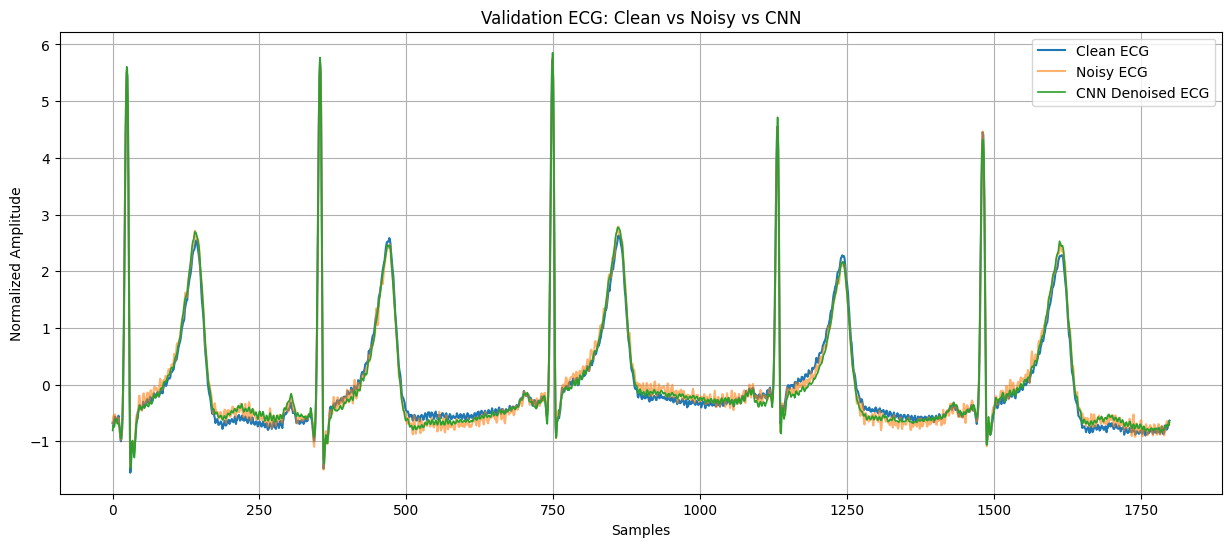

In [95]:
import matplotlib.pyplot as plt

sample = 0

plt.figure(figsize=(15, 6))

plt.plot(
    val_clean[sample].flatten(),
    label="Clean ECG",
    linewidth=1.5
)

plt.plot(
    val_noisy[sample].flatten(),
    label="Noisy ECG",
    alpha=0.6
)

plt.plot(
    val_predictions[sample].flatten(),
    label="CNN Denoised ECG",
    linewidth=1.2
)

plt.title("Validation ECG: Clean vs Noisy vs CNN")
plt.xlabel("Samples")
plt.ylabel("Normalized Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [96]:
sample = 0

print("Sample | Clean | Noisy | CNN")
print("-----------------------------")

for i in range(30):
    print(
        i,
        round(float(val_clean[sample, i, 0]), 3),
        round(float(val_noisy[sample, i, 0]), 3),
        round(float(val_predictions[sample, i, 0]), 3)
    )

Sample | Clean | Noisy | CNN
-----------------------------
0 -0.681 -0.682 -0.81
1 -0.695 -0.571 -0.717
2 -0.651 -0.54 -0.743
3 -0.608 -0.546 -0.748
4 -0.564 -0.525 -0.668
5 -0.578 -0.598 -0.608
6 -0.622 -0.684 -0.649
7 -0.637 -0.638 -0.61
8 -0.637 -0.581 -0.689
9 -0.593 -0.58 -0.69
10 -0.549 -0.591 -0.679
11 -0.651 -0.691 -0.729
12 -0.797 -0.81 -0.745
13 -0.928 -0.917 -0.841
14 -1.001 -0.977 -0.952
15 -0.958 -0.938 -0.883
16 -0.826 -0.797 -0.742
17 -0.593 -0.519 -0.366
18 -0.024 0.092 0.254
19 0.836 0.94 0.95
20 2.061 2.08 1.972
21 3.271 3.203 3.197
22 4.365 4.323 4.311
23 5.108 5.161 5.124
24 5.502 5.549 5.607
25 5.458 5.418 5.556
26 4.875 4.842 4.828
27 3.446 3.502 3.363
28 1.58 1.649 1.484
29 -0.287 -0.24 -0.214


In [97]:
sample = 0

clean = val_clean[sample].flatten()
noisy = val_noisy[sample].flatten()
cnn = val_predictions[sample].flatten()

print("Clean maximum:", np.max(clean))
print("Noisy maximum:", np.max(noisy))
print("CNN maximum:", np.max(cnn))

print("\nClean minimum:", np.min(clean))
print("Noisy minimum:", np.min(noisy))
print("CNN minimum:", np.min(cnn))

print("\nClean MSE:", np.mean((clean - clean)**2))
print("Noisy MSE:", np.mean((noisy - clean)**2))
print("CNN MSE:", np.mean((cnn - clean)**2))

Clean maximum: 5.7355113
Noisy maximum: 5.764373
CNN maximum: 5.854813

Clean minimum: -1.5554445
Noisy minimum: -1.5004449
CNN minimum: -1.4806479

Clean MSE: 0.0
Noisy MSE: 0.014952885
CNN MSE: 0.01349383


In [98]:
val_noisy_errors = np.mean(
    (val_noisy - val_clean) ** 2,
    axis=(1, 2)
)

val_cnn_errors = np.mean(
    (val_predictions - val_clean) ** 2,
    axis=(1, 2)
)

difference = val_cnn_errors - val_noisy_errors

worst_indices = np.argsort(difference)[-5:][::-1]

print("FIVE WORST VALIDATION WINDOWS")
print("--------------------------------")

for idx in worst_indices:
    print(
        f"Window: {idx} | "
        f"Noisy MSE: {val_noisy_errors[idx]:.6f} | "
        f"CNN MSE: {val_cnn_errors[idx]:.6f} | "
        f"Difference: {difference[idx]:.6f}"
    )

FIVE WORST VALIDATION WINDOWS
--------------------------------
Window: 245 | Noisy MSE: 0.015129 | CNN MSE: 0.051320 | Difference: 0.036192
Window: 220 | Noisy MSE: 0.015167 | CNN MSE: 0.050767 | Difference: 0.035600
Window: 197 | Noisy MSE: 0.014979 | CNN MSE: 0.049975 | Difference: 0.034996
Window: 232 | Noisy MSE: 0.014807 | CNN MSE: 0.047558 | Difference: 0.032751
Window: 195 | Noisy MSE: 0.015000 | CNN MSE: 0.045792 | Difference: 0.030792


In [99]:
# Calculate MSE for each validation window
noisy_errors = np.mean(
    (val_noisy - val_clean) ** 2,
    axis=(1, 2)
)

cnn_errors = np.mean(
    (val_predictions - val_clean) ** 2,
    axis=(1, 2)
)

# First 150 windows: Record 113
# Next 150 windows: Record 114

for name, start, end in [
    ("Record 113", 0, 150),
    ("Record 114", 150, 300)
]:

    noisy = noisy_errors[start:end]
    cnn = cnn_errors[start:end]

    print("\n", name)
    print("-" * 35)

    print("Noisy MSE:", np.mean(noisy))
    print("CNN MSE:", np.mean(cnn))

    print("Improved windows:",
          np.sum(cnn < noisy))

    print("Worsened windows:",
          np.sum(cnn > noisy))

    improvement = (
        (np.mean(noisy) - np.mean(cnn))
        / np.mean(noisy)
    ) * 100

    print("MSE improvement (%):", improvement)


 Record 113
-----------------------------------
Noisy MSE: 0.014997638
CNN MSE: 0.013881567
Improved windows: 126
Worsened windows: 24
MSE improvement (%): 7.441644

 Record 114
-----------------------------------
Noisy MSE: 0.014993388
CNN MSE: 0.03150399
Improved windows: 1
Worsened windows: 149
MSE improvement (%): -110.119225


In [100]:
def signal_summary(name, clean, noisy, predictions=None):
    print(f"\n{name}")
    print("-" * 40)

    print("Clean mean:", np.mean(clean))
    print("Clean STD:", np.mean(np.std(clean, axis=(1, 2))))
    print("Clean minimum:", np.min(clean))
    print("Clean maximum:", np.max(clean))

    print("Noisy-clean noise STD:",
          np.mean(np.std(noisy - clean, axis=(1, 2))))

    if predictions is not None:
        print("CNN-clean correlation:",
              np.mean([
                  np.corrcoef(
                      clean[i].flatten(),
                      predictions[i].flatten()
                  )[0, 1]
                  for i in range(len(clean))
              ]))

signal_summary(
    "TRAINING",
    train_clean, train_noisy
)

signal_summary(
    "VALIDATION RECORD 113",
    val_clean[:150], val_noisy[:150],
    val_predictions[:150]
)

signal_summary(
    "VALIDATION RECORD 114",
    val_clean[150:], val_noisy[150:],
    val_predictions[150:]
)


TRAINING
----------------------------------------
Clean mean: -5.8845235e-09
Clean STD: 1.0
Clean minimum: -5.8160715
Clean maximum: 8.595362
Noisy-clean noise STD: 0.12097346

VALIDATION RECORD 113
----------------------------------------
Clean mean: -2.7409306e-09
Clean STD: 1.0
Clean minimum: -2.1536245
Clean maximum: 6.6006227
Noisy-clean noise STD: 0.12096547
CNN-clean correlation: 0.9931468826646179

VALIDATION RECORD 114
----------------------------------------
Clean mean: -5.312319e-09
Clean STD: 1.0
Clean minimum: -8.07768
Clean maximum: 8.207673
Noisy-clean noise STD: 0.12094752
CNN-clean correlation: 0.9844774169002812


In [101]:
# Compare the distribution of absolute amplitudes

for name, data in [
    ("Training", train_clean),
    ("Record 113", val_clean[:150]),
    ("Record 114", val_clean[150:])
]:

    amplitudes = np.abs(data.flatten())

    print("\n", name)
    print("----------------------")

    print("50th percentile:",
          np.percentile(amplitudes, 50))

    print("90th percentile:",
          np.percentile(amplitudes, 90))

    print("95th percentile:",
          np.percentile(amplitudes, 95))

    print("99th percentile:",
          np.percentile(amplitudes, 99))


 Training
----------------------
50th percentile: 0.41170055
90th percentile: 1.250434
95th percentile: 1.9164212
99th percentile: 4.250972

 Record 113
----------------------
50th percentile: 0.51113117
90th percentile: 1.3959414
95th percentile: 2.1135101
99th percentile: 4.451391

 Record 114
----------------------
50th percentile: 0.49986202
90th percentile: 1.5271666
95th percentile: 2.0852098
99th percentile: 3.565501


In [102]:
from scipy.signal import welch

def frequency_analysis(name, data):
    signal = data[0].flatten()

    frequencies, power = welch(
        signal,
        fs=360,
        nperseg=1024
    )

    bands = {
        "0-5 Hz": (0, 5),
        "5-15 Hz": (5, 15),
        "15-40 Hz": (15, 40),
        "40-100 Hz": (40, 100),
        "100-180 Hz": (100, 180)
    }

    print("\n", name)
    print("-------------------------")

    total_power = np.sum(power)

    for band, (low, high) in bands.items():
        mask = (frequencies >= low) & (frequencies < high)

        band_power = np.sum(power[mask])

        percentage = (band_power / total_power) * 100

        print(f"{band}: {percentage:.2f}%")

frequency_analysis("TRAINING", train_clean)
frequency_analysis("RECORD 113", val_clean[:150])
frequency_analysis("RECORD 114", val_clean[150:])


 TRAINING
-------------------------
0-5 Hz: 21.12%
5-15 Hz: 36.77%
15-40 Hz: 40.29%
40-100 Hz: 1.77%
100-180 Hz: 0.05%

 RECORD 113
-------------------------
0-5 Hz: 57.77%
5-15 Hz: 23.05%
15-40 Hz: 18.41%
40-100 Hz: 0.75%
100-180 Hz: 0.02%

 RECORD 114
-------------------------
0-5 Hz: 65.26%
5-15 Hz: 17.98%
15-40 Hz: 14.58%
40-100 Hz: 2.12%
100-180 Hz: 0.07%


In [103]:
from scipy.signal import welch

def average_frequency_analysis(name, data):

    bands = {
        "0-5 Hz": (0, 5),
        "5-15 Hz": (5, 15),
        "15-40 Hz": (15, 40),
        "40-100 Hz": (40, 100),
        "100-180 Hz": (100, 180)
    }

    band_percentages = {band: [] for band in bands}

    for window in data:

        signal = window.flatten()

        frequencies, power = welch(
            signal,
            fs=360,
            nperseg=1024
        )

        total_power = np.sum(power)

        for band, (low, high) in bands.items():

            mask = (
                (frequencies >= low) &
                (frequencies < high)
            )

            percentage = (
                np.sum(power[mask]) /
                (total_power + 1e-12)
            ) * 100

            band_percentages[band].append(percentage)

    print("\n", name)
    print("-" * 40)

    for band in bands:

        print(
            f"{band}: "
            f"{np.mean(band_percentages[band]):.2f}%"
        )


average_frequency_analysis("TRAINING", train_clean)
average_frequency_analysis("RECORD 113", val_clean[:150])
average_frequency_analysis("RECORD 114", val_clean[150:])


 TRAINING
----------------------------------------
0-5 Hz: 46.84%
5-15 Hz: 37.62%
15-40 Hz: 14.69%
40-100 Hz: 0.82%
100-180 Hz: 0.03%

 RECORD 113
----------------------------------------
0-5 Hz: 53.75%
5-15 Hz: 25.53%
15-40 Hz: 20.08%
40-100 Hz: 0.62%
100-180 Hz: 0.02%

 RECORD 114
----------------------------------------
0-5 Hz: 64.81%
5-15 Hz: 15.43%
15-40 Hz: 17.74%
40-100 Hz: 1.92%
100-180 Hz: 0.10%


In [104]:
from scipy.signal import welch

low_freq_errors = []
high_freq_errors = []

for i in range(len(val_clean)):

    signal = val_clean[i].flatten()

    frequencies, power = welch(
        signal,
        fs=360,
        nperseg=1024
    )

    low_power = np.sum(power[frequencies < 5])
    high_power = np.sum(power[frequencies >= 5])

    low_ratio = low_power / (low_power + high_power + 1e-12)

    if low_ratio >= 0.60:
        low_freq_errors.append(
            val_cnn_errors[i]
        )
    else:
        high_freq_errors.append(
            val_cnn_errors[i]
        )

print("LOW-FREQUENCY DOMINANT WINDOWS")
print("--------------------------------")
print("Count:", len(low_freq_errors))
print("Average CNN MSE:", np.mean(low_freq_errors))

print("\nOTHER WINDOWS")
print("--------------------------------")
print("Count:", len(high_freq_errors))
print("Average CNN MSE:", np.mean(high_freq_errors))

LOW-FREQUENCY DOMINANT WINDOWS
--------------------------------
Count: 116
Average CNN MSE: 0.030787624

OTHER WINDOWS
--------------------------------
Count: 184
Average CNN MSE: 0.017589508


In [105]:
from scipy.signal import welch

groups = {
    "Record 113": [],
    "Record 114": []
}

for i in range(len(val_clean)):

    signal = val_clean[i].flatten()

    frequencies, power = welch(
        signal,
        fs=360,
        nperseg=1024
    )

    total_power = np.sum(power)
    low_power = np.sum(power[frequencies < 5])

    low_ratio = low_power / (total_power + 1e-12)

    record = "Record 113" if i < 150 else "Record 114"
    category = "Low-frequency" if low_ratio >= 0.60 else "Other"

    groups[record].append((category, i))


for record, windows in groups.items():

    print("\n", record)
    print("=" * 45)

    for category in ["Low-frequency", "Other"]:

        indices = [
            i for cat, i in windows if cat == category
        ]

        if not indices:
            print(category, ": No windows")
            continue

        noisy_mse = val_noisy_errors[indices]
        cnn_mse = val_cnn_errors[indices]

        improved = np.sum(cnn_mse < noisy_mse)

        print("\n", category)
        print("Window count:", len(indices))
        print("Noisy MSE:", np.mean(noisy_mse))
        print("CNN MSE:", np.mean(cnn_mse))
        print("Improved:", improved)
        print("Worsened:", np.sum(cnn_mse > noisy_mse))


 Record 113

 Low-frequency
Window count: 12
Noisy MSE: 0.01503237
CNN MSE: 0.015576751
Improved: 5
Worsened: 7

 Other
Window count: 138
Noisy MSE: 0.014994618
CNN MSE: 0.013734162
Improved: 121
Worsened: 17

 Record 114

 Low-frequency
Window count: 104
Noisy MSE: 0.014994578
CNN MSE: 0.032542728
Improved: 1
Worsened: 103

 Other
Window count: 46
Noisy MSE: 0.014990694
CNN MSE: 0.02915555
Improved: 0
Worsened: 46


In [106]:
# Compare mean and standard deviation of prediction errors

for name, start, end in [
    ("Record 113", 0, 150),
    ("Record 114", 150, 300)
]:

    clean = val_clean[start:end]
    noisy = val_noisy[start:end]
    pred = val_predictions[start:end]

    noisy_error = noisy - clean
    cnn_error = pred - clean

    print("\n", name)
    print("=" * 40)

    print("Mean noisy error:",
          np.mean(noisy_error))

    print("Mean CNN error:",
          np.mean(cnn_error))

    print("STD noisy error:",
          np.std(noisy_error))

    print("STD CNN error:",
          np.std(cnn_error))

    print("Mean absolute CNN error:",
          np.mean(np.abs(cnn_error)))


 Record 113
Mean noisy error: 0.019095268
Mean CNN error: 0.008674539
STD noisy error: 0.12096697
STD CNN error: 0.1175003
Mean absolute CNN error: 0.09824989

 Record 114
Mean noisy error: 0.019098759
Mean CNN error: 0.0067515248
STD noisy error: 0.12094885
STD CNN error: 0.17736518
Mean absolute CNN error: 0.12788658


In [107]:
for name, start, end in [
    ("Record 113", 0, 150),
    ("Record 114", 150, 300)
]:

    errors = val_cnn_errors[start:end]

    print("\n", name)
    print("-" * 40)

    print("Minimum MSE:", np.min(errors))
    print("25th percentile:", np.percentile(errors, 25))
    print("Median MSE:", np.median(errors))
    print("75th percentile:", np.percentile(errors, 75))
    print("90th percentile:", np.percentile(errors, 90))
    print("Maximum MSE:", np.max(errors))


 Record 113
----------------------------------------
Minimum MSE: 0.010694478
25th percentile: 0.012913603
Median MSE: 0.013778803
75th percentile: 0.0145938145
90th percentile: 0.01570433
Maximum MSE: 0.02226502

 Record 114
----------------------------------------
Minimum MSE: 0.013931446
25th percentile: 0.025503153
Median MSE: 0.031146891
75th percentile: 0.036651958
90th percentile: 0.041896906
Maximum MSE: 0.05132035


In [108]:
import wfdb

record_list = wfdb.get_record_list("mitdb")

print("Total available records:", len(record_list))
print(record_list)

Total available records: 48
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']


In [109]:
import wfdb

all_records = wfdb.get_record_list("mitdb")

for rid in all_records:
    record = wfdb.rdrecord(rid, pn_dir="mitdb")

    print(
        "Record:", rid,
        "| Sampling frequency:", record.fs,
        "| Channels:", record.sig_name,
        "| Units:", record.units
    )

Record: 100 | Sampling frequency: 360 | Channels: ['MLII', 'V5'] | Units: ['mV', 'mV']
Record: 101 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 102 | Sampling frequency: 360 | Channels: ['V5', 'V2'] | Units: ['mV', 'mV']
Record: 103 | Sampling frequency: 360 | Channels: ['MLII', 'V2'] | Units: ['mV', 'mV']
Record: 104 | Sampling frequency: 360 | Channels: ['V5', 'V2'] | Units: ['mV', 'mV']
Record: 105 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 106 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 107 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 108 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 109 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 111 | Sampling frequency: 360 | Channels: ['MLII', 'V1'] | Units: ['mV', 'mV']
Record: 112 | Sampling frequency: 360 | Channel

In [121]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Flatten ECG arrays
clean = val_clean.reshape(-1)
noisy = val_noisy.reshape(-1)
denoised = val_predictions.reshape(-1)

# Calculate MSE
noisy_mse = mean_squared_error(clean, noisy)
denoised_mse = mean_squared_error(clean, denoised)

# Calculate MAE
noisy_mae = mean_absolute_error(clean, noisy)
denoised_mae = mean_absolute_error(clean, denoised)

# Calculate RMSE
noisy_rmse = np.sqrt(noisy_mse)
denoised_rmse = np.sqrt(denoised_mse)

print("VALIDATION PERFORMANCE")
print("----------------------")
print("Noisy ECG MSE:", noisy_mse)
print("Denoised ECG MSE:", denoised_mse)

print("\nNoisy ECG MAE:", noisy_mae)
print("Denoised ECG MAE:", denoised_mae)

print("\nNoisy ECG RMSE:", noisy_rmse)
print("Denoised ECG RMSE:", denoised_rmse)

VALIDATION PERFORMANCE
----------------------
Noisy ECG MSE: 0.015012599527835846
Denoised ECG MSE: 0.012585561722517014

Noisy ECG MAE: 0.10395201295614243
Denoised ECG MAE: 0.09261535853147507

Noisy ECG RMSE: 0.12252591369924913
Denoised ECG RMSE: 0.11218538996909096


AVERAGE SNR
--------------------
Noisy ECG SNR: 18.235605 dB
Denoised ECG SNR: 19.111427 dB
SNR Improvement: 0.87582356 dB


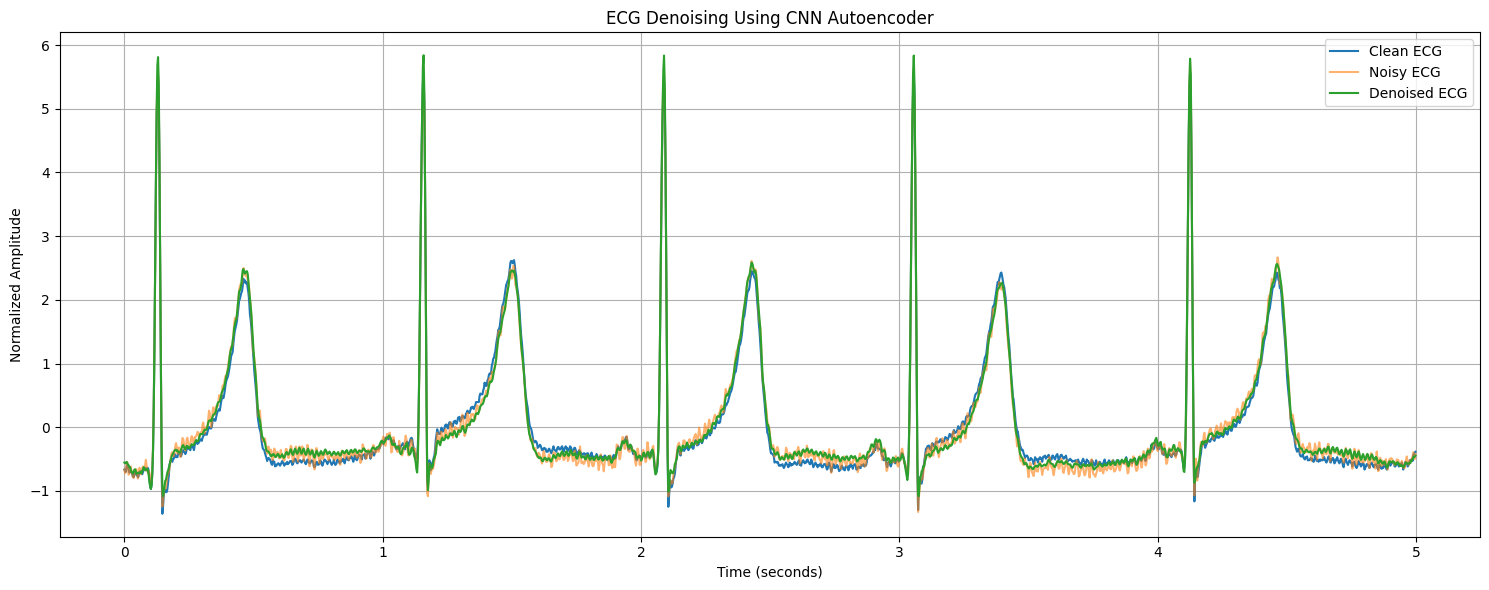

In [122]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate SNR for each ECG window
def calculate_snr(clean, reconstructed):
    signal_power = np.sum(clean ** 2, axis=(1, 2))
    noise_power = np.sum((clean - reconstructed) ** 2, axis=(1, 2))
    return 10 * np.log10(
        (signal_power + 1e-10) / (noise_power + 1e-10)
    )

noisy_snr = calculate_snr(val_clean, val_noisy)
denoised_snr = calculate_snr(val_clean, val_predictions)

print("AVERAGE SNR")
print("--------------------")
print("Noisy ECG SNR:", np.mean(noisy_snr), "dB")
print("Denoised ECG SNR:", np.mean(denoised_snr), "dB")
print("SNR Improvement:", np.mean(denoised_snr - noisy_snr), "dB")

# Plot one ECG window
sample = 0
time = np.arange(1800) / 360

plt.figure(figsize=(15, 6))
plt.plot(time, val_clean[sample, :, 0], label="Clean ECG")
plt.plot(time, val_noisy[sample, :, 0], label="Noisy ECG", alpha=0.6)
plt.plot(time, val_predictions[sample, :, 0], label="Denoised ECG")

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.title("ECG Denoising Using CNN Autoencoder")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [123]:
# Load best saved model
test_predictions = best_model.predict(
    test_noisy,
    verbose=1
)

print("Test prediction shape:", test_predictions.shape)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step
Test prediction shape: (300, 1800, 1)


In [124]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

clean = test_clean.reshape(-1)
noisy = test_noisy.reshape(-1)
denoised = test_predictions.reshape(-1)

noisy_mse = mean_squared_error(clean, noisy)
denoised_mse = mean_squared_error(clean, denoised)

noisy_mae = mean_absolute_error(clean, noisy)
denoised_mae = mean_absolute_error(clean, denoised)

noisy_rmse = np.sqrt(noisy_mse)
denoised_rmse = np.sqrt(denoised_mse)

print("FINAL TEST PERFORMANCE")
print("----------------------")
print("Noisy MSE:", noisy_mse)
print("Denoised MSE:", denoised_mse)
print("Noisy MAE:", noisy_mae)
print("Denoised MAE:", denoised_mae)
print("Noisy RMSE:", noisy_rmse)
print("Denoised RMSE:", denoised_rmse)

noisy_snr = calculate_snr(test_clean, test_noisy)
denoised_snr = calculate_snr(test_clean, test_predictions)

print("\nNoisy SNR:", np.mean(noisy_snr), "dB")
print("Denoised SNR:", np.mean(denoised_snr), "dB")
print("SNR Improvement:", np.mean(denoised_snr - noisy_snr), "dB")

FINAL TEST PERFORMANCE
----------------------
Noisy MSE: 0.014993016608059406
Denoised MSE: 0.013065170496702194
Noisy MAE: 0.10387792438268661
Denoised MAE: 0.09367269277572632
Noisy RMSE: 0.12244597424194642
Denoised RMSE: 0.11430297676220945

Noisy SNR: 18.241272 dB
Denoised SNR: 18.916056 dB
SNR Improvement: 0.67478496 dB


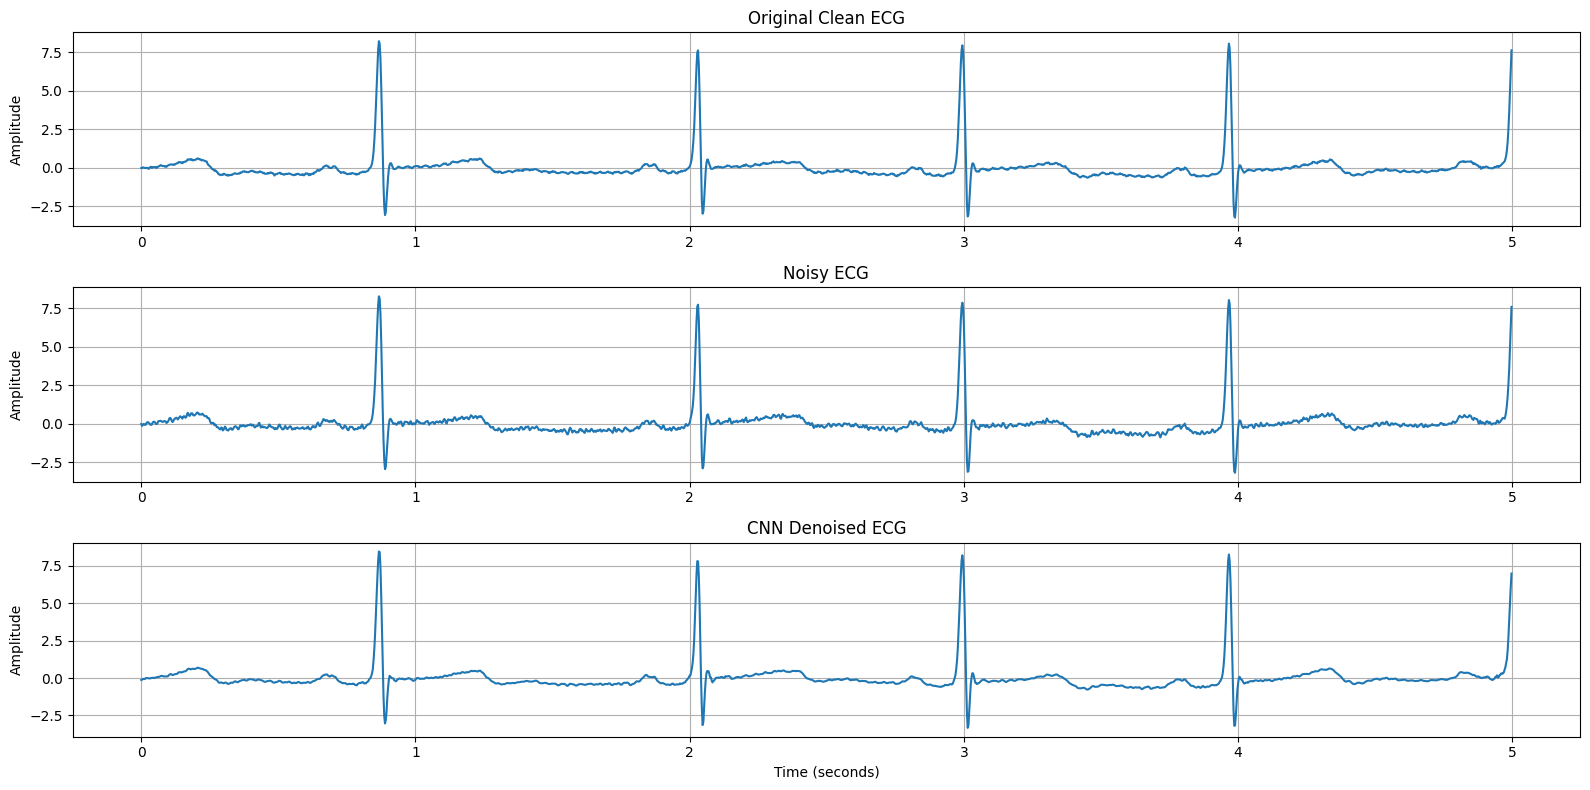

<Figure size 640x480 with 0 Axes>

In [127]:
import matplotlib.pyplot as plt
import numpy as np

sample = 0
time = np.arange(1800) / 360

plt.figure(figsize=(16, 8))

plt.subplot(3, 1, 1)
plt.plot(time, test_clean[sample, :, 0])
plt.title("Original Clean ECG")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(time, test_noisy[sample, :, 0])
plt.title("Noisy ECG")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(time, test_predictions[sample, :, 0])
plt.title("CNN Denoised ECG")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()
plt.savefig("ECG_Denoising_Comparison.png", dpi=300, bbox_inches="tight")

In [128]:
# Calculate PRD for test signals

clean = test_clean.reshape(-1)
noisy = test_noisy.reshape(-1)
denoised = test_predictions.reshape(-1)

noisy_prd = (
    np.sqrt(np.sum((clean - noisy)**2) /
            np.sum(clean**2)) * 100
)

denoised_prd = (
    np.sqrt(np.sum((clean - denoised)**2) /
            np.sum(clean**2)) * 100
)

print("Noisy ECG PRD:", noisy_prd, "%")
print("Denoised ECG PRD:", denoised_prd, "%")

Noisy ECG PRD: 12.244597 %
Denoised ECG PRD: 11.430298 %


In [126]:
best_model.save("Final_ECG_Denoising_Model.keras")